# Project 11: Adverse Weather Robustness Benchmark (v4.0)

## Obiettivo del progetto

Il sistema scelto è una pipeline di Pedestrian Detection costruita su CARLA: un sensore camera RGB frontale acquisisce i frame della scena simulata, che vengono poi elaborati in tempo reale da YOLOv8n per rilevare la presenza di pedoni. L'obiettivo del benchmark è misurare come le prestazioni di questo sistema (detection rate, confidenza, warning delay, miss rate) degradano al variare delle condizioni ambientali (pioggia, nebbia, notte, backlight) e in presenza di blur ottico (mild e severe), come richiesto dalla traccia del progetto.

## Condizioni Testate

### Condizioni Ambientali (parametri meteo CARLA)

| Condizione | Descrizione |
|---|---|
| **Clear** | Cielo sereno, sole alto (70°) |
| **Rain** | Pioggia intensa (95%), nuvole (90%), pozzanghere e strada bagnata (100%) |
| **Fog** | Nebbia densa (densità 45, distanza 25m) |
| **Night** | Sole sotto l'orizzonte (-25°) |
| **Backlight** | Sole basso (8°) davanti alla camera (azimut calibrato per spawn point), controluce |
| **Rain severe** | Temporale al crepuscolo: pioggia e vento al massimo, cielo coperto, foschia, sole a 3° |
| **Fog severe** | Nebbia fittissima (densità 90, distanza 5 m): visibilità di pochi metri |
| **Night severe** | Notte con i lampioni spenti: la scena è illuminata solo dai fari dell'ego |

Le condizioni *severe* servono a trovare le **soglie di fallimento**: le versioni base di CARLA sono abbastanza leggere da non mettere in difficoltà il detector nella zona critica.

### Corruzione Visiva: Blur (post-processing sull'immagine catturata)

Come richiesto dalla traccia (*"Add mild and severe visual corruptions to identify clear failure thresholds"*), viene applicato **Gaussian Blur** a due livelli di severità:

| Corruzione | Severità | Cosa simula |
|---|---|---|
| **Blur mild** | 1 | Lente leggermente sporca o condensa |
| **Blur severe** | 2 | Lente molto sporca o fuori fuoco |

**Totale: 10 condizioni** (5 meteo base + 3 meteo severo + 2 blur a severità crescente). Velocità di crociera: 40 km/h.

Il blur viene applicato in post-processing sul frame catturato dalla camera in condizione **clear**, così da isolare l'effetto della corruzione senza mescolare gli effetti del meteo.


## Metriche Raccolte

| Metrica | Descrizione |
|---|---|
| **Detection Rate (recall)** | Percentuale dei frame con pedone visibile in cui il pedone è stato rilevato correttamente (associato alla ground truth CARLA) |
| **Precision** | Frazione delle detection accettate che corrispondono davvero al target |
| **First Detection Distance** | Distanza (in metri) alla quale il sistema rileva il pedone per la prima volta |
| **Confidence** | Confidenza di YOLOv8n sulla detection associata al pedone |
| **Warning (FCW)** | Time-to-collision al primo warning, ritardo rispetto all'ingresso nella zona di warning, e se il veicolo riesce a fermarsi in tempo |
| **Miss Rate** | Percentuale di frame nella zona critica, con pedone visibile, in cui il pedone NON è stato rilevato |
| **False Positive Count** | Numero di detection "person" che non corrispondono al pedone reale (es. dissuasori, arredo urbano) |
| **Min Distance** | Distanza minima raggiunta tra veicolo e pedone prima dello stop |

Le metriche vengono registrate **frame-by-frame** e aggregate per ogni condizione, permettendo di tracciare curve di degradazione e identificare le soglie di fallimento del sistema.

### Deliverables
1. Benchmark scripts eseguibili (self-contained notebook)
2. Codice CARLA per gestione scenario e meteo
3. Report con metodologia, metriche e **failure cases**
4. Confronti side-by-side visuali
5. Grafici di degradazione con **soglie di collasso**
6. Tabelle con esito OK / DEGRADATO / COLLASSO per ogni condizione
7. Modulo FCW (pedone) e Red Light Warning (semaforo) basati sul time-to-collision

---

## 1. Setup Ambiente e Dipendenze

Prima di iniziare, assicuriamoci di avere tutte le librerie necessarie installate.

**Requisiti**:
- Python 3.7 o 3.8
- CARLA Simulator in esecuzione su `localhost:2000`
- Pacchetti: `carla`, `ultralytics`, `opencv-python`, `pandas`, `matplotlib`, `pillow`, `seaborn`

## 1.1 Fix Dipendenze (se necessario)

Se riscontri errori di import con `urllib3` e OpenSSL, esegui questa cella per downgrade alla versione compatibile.

In [ ]:
# Fix compatibilità dipendenze per Python 3.7
import sys
!{sys.executable} -m pip install --upgrade "urllib3<2.0" "typing-extensions>=4.0" "tabulate" "seaborn" "matplotlib-inline==0.1.6" --quiet

print("Dipendenze fixate:")
print("   - urllib3 < 2.0 (compatibilità OpenSSL)")
print("   - typing-extensions >= 4.0 (backport typing per Python 3.7)")
print("   - tabulate (per report markdown)")
print("   - seaborn (per heatmap)")
print("   - matplotlib-inline 0.1.6 (le versioni nuove non funzionano con matplotlib 3.5: riavviare il kernel)")

In [ ]:
%pip install -r requirements.txt

In [2]:
# Verifica versione Python
import sys
print(f"Python version: {sys.version}")

# Fix per typing.OrderedDict in Python 3.7
import typing
if not hasattr(typing, 'OrderedDict'):
    from collections import OrderedDict as CollectionsOrderedDict
    typing.OrderedDict = CollectionsOrderedDict
    print("Monkey-patch applicato: typing.OrderedDict aggiunto manualmente")

# FIX CRUCIALE PER WINDOWS: OpenMP e PyTorch PRIMA di matplotlib/seaborn
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import torch
print("--- HARDWARE ACCELERATION CHECK ---")
print(f"CUDA (Nvidia GPU) available: {torch.cuda.is_available()}")
if hasattr(torch.backends, 'mps'):
    print(f"MPS (Apple Silicon GPU) available: {torch.backends.mps.is_available()}")
print("-----------------------------------")

# Importa librerie principali
import csv
import queue
import time
import glob
import json
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image, ImageFilter, ImageEnhance
from ultralytics import YOLO

import carla
# Stile plot
plt.style.use('seaborn-whitegrid')
sns.set_palette("husl")

print("✅ Tutte le librerie importate con successo")


Python version: 3.10.21 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:35:39) [MSC v.1942 64 bit (AMD64)]
--- HARDWARE ACCELERATION CHECK ---
CUDA (Nvidia GPU) available: True
MPS (Apple Silicon GPU) available: False
-----------------------------------
✅ Tutte le librerie importate con successo


## 2. Configurazione Connessione CARLA

Connettiamoci al server CARLA e verifichiamo che sia raggiungibile.

**Nota**: Il server CARLA deve essere già avviato prima di eseguire questa cella.

In [60]:
# Configurazione connessione
CARLA_HOST = 'localhost'
CARLA_PORT = 2000
CARLA_TIMEOUT = 20.0

try:
    client = carla.Client(CARLA_HOST, CARLA_PORT)
    client.set_timeout(CARLA_TIMEOUT)
    world = client.get_world()
    
    print(f" Connesso a CARLA")
    print(f"   Client version: {client.get_client_version()}")
    print(f"   Server version: {client.get_server_version()}")
    print(f"   Mappa corrente: {world.get_map().name}")
    
except RuntimeError as e:
    print(f"Errore di connessione: {e}")
    print(f"   Verifica che CARLA sia in esecuzione su {CARLA_HOST}:{CARLA_PORT}")

 Connesso a CARLA
   Client version: 0.9.16
   Server version: 0.9.16
   Mappa corrente: Carla/Maps/Town10HD_Opt


## 3. Definizione Condizioni Meteo

Creiamo una funzione per gestire le diverse condizioni meteorologiche in modo consistente.

**Parametri CARLA controllati**:
- Cloudiness, precipitation, fog density, sun position, wetness, wind intensity

Tutti i parametri sono scritti in modo esplicito a partire da una base comune (= clear) e ogni chiamata crea un **nuovo** oggetto `carla.WeatherParameters`. I preset di CARLA (`ClearNoon`, ...) sono oggetti condivisi: modificarli "contamina" le condizioni eseguite dopo (nelle versioni precedenti la nebbia del test fog finiva anche nel test backlight).

In [61]:
# Ordine e nomi dei parametri di carla.WeatherParameters (CARLA 0.9.16)
WEATHER_FIELDS = (
    'cloudiness', 'precipitation', 'precipitation_deposits', 'wind_intensity',
    'sun_azimuth_angle', 'sun_altitude_angle',
    'fog_density', 'fog_distance', 'fog_falloff', 'wetness',
    'scattering_intensity', 'mie_scattering_scale', 'rayleigh_scattering_scale',
    'dust_storm',
)

# Base comune (= clear): ogni condizione sovrascrive solo cio' che la caratterizza
BASE_WEATHER = {
    'cloudiness': 0.0,
    'precipitation': 0.0,
    'precipitation_deposits': 0.0,
    'wind_intensity': 0.0,
    'sun_azimuth_angle': 0.0,
    'sun_altitude_angle': 70.0,
    'fog_density': 0.0,
    'fog_distance': 0.0,
    'fog_falloff': 0.0,
    'wetness': 0.0,
    'scattering_intensity': 1.0,
    'mie_scattering_scale': 0.03,
    'rayleigh_scattering_scale': 0.0331,
    'dust_storm': 0.0,
}

WEATHER_OVERRIDES = {
    'clear': {},
    'rain': {
        'cloudiness': 90.0,
        'precipitation': 95.0,
        'precipitation_deposits': 90.0,
        'wind_intensity': 100.0,
        'wetness': 100.0,
        'fog_density': 8.0,
    },
    'fog': {
        'fog_density': 45.0,
        'fog_distance': 25.0,
        'fog_falloff': 1.5,
    },
    'night': {
        'sun_altitude_angle': -25.0,
    },
    # --- Livelli severi: stessa condizione, molto piu' pesante ---
    'rain_severe': {               # temporale al crepuscolo: pioggia massima, cielo coperto, poca luce
        'cloudiness': 100.0,
        'precipitation': 100.0,
        'precipitation_deposits': 100.0,
        'wind_intensity': 100.0,
        'wetness': 100.0,
        'fog_density': 25.0,
        'fog_distance': 10.0,
        'sun_altitude_angle': 3.0,
    },
    'fog_severe': {                # nebbia fittissima: visibilita' di pochi metri
        'fog_density': 90.0,
        'fog_distance': 5.0,
        'fog_falloff': 1.5,
    },
    'night_severe': {              # notte senza lampioni (vedi STREET_LIGHTS_OFF): solo i fari dell'ego
        'sun_altitude_angle': -25.0,
        'cloudiness': 80.0,
    },
    'backlight': {
        'sun_azimuth_angle': 180.0,  # sostituito da (yaw ego + offset dello spawn) quando lo yaw e' noto
        'sun_altitude_angle': 8.0,   # sole basso: entro il campo visivo verticale della camera
    },
}

# Condizioni in cui i lampioni della citta' restano SPENTI anche di notte
STREET_LIGHTS_OFF = {'night_severe'}

# Azimut del sole relativo alla direzione di marcia dell'ego per avere il sole DAVANTI
# alla camera (controluce), per spawn point. Valori scelti con la calibrazione dello smoke
# test (Sezione 10): l'offset in cui il sole compare nell'inquadratura. Il valore cambia
# con lo spawn perche' la convenzione dell'azimut del sole in CARLA non segue lo yaw.
BACKLIGHT_AZIMUTH_OFFSET = {0: 180.0, 103: 0.0}   # {spawn point: offset in gradi}


def backlight_offset(spawn_index):
    """Offset di azimut del sole per lo spawn point (180 se lo spawn non e' calibrato)."""
    return BACKLIGHT_AZIMUTH_OFFSET.get(spawn_index, 180.0)


def weather_params(weather_type, ego_yaw=None, spawn_index=None):
    """
    Dizionario completo dei parametri meteo per una condizione.

    Args:
        weather_type (str): una chiave di WEATHER_OVERRIDES ('clear', 'fog', 'fog_severe', ...)
        ego_yaw (float): yaw (gradi) dell'ego vehicle; per 'backlight' orienta il sole
                         davanti alla camera
        spawn_index (int): spawn point dell'ego, per l'offset calibrato del backlight
    """
    weather_type = weather_type.lower()
    if weather_type not in WEATHER_OVERRIDES:
        raise ValueError(f"Condizione meteo sconosciuta: {weather_type}")
    params = dict(BASE_WEATHER)
    params.update(WEATHER_OVERRIDES[weather_type])
    if weather_type == 'backlight' and ego_yaw is not None:
        params['sun_azimuth_angle'] = round((ego_yaw + backlight_offset(spawn_index)) % 360.0, 2)
    return params


def set_street_lights(world, weather_type, params):
    """
    Lampioni della citta' in modo esplicito e ripetibile: accesi solo di notte (sole sotto
    l'orizzonte) e spenti nelle condizioni di STREET_LIGHTS_OFF. Il ciclo giorno/notte
    automatico di CARLA viene disattivato, altrimenti riaccenderebbe le luci da solo.
    Da chiamare DOPO world.set_weather(). Restituisce 'on', 'off' o 'error'.
    """
    on = params['sun_altitude_angle'] < 0 and weather_type not in STREET_LIGHTS_OFF
    try:
        lm = world.get_lightmanager()
        lm.set_day_night_cycle(False)
        lights = lm.get_all_lights(carla.LightGroup.Street)
        if on:
            lm.turn_on(lights)
        else:
            lm.turn_off(lights)
        return 'on' if on else 'off'
    except Exception as exc:
        print(f"  [WARN] impossibile impostare i lampioni: {exc}")
        return 'error'


def build_weather(weather_type, ego_yaw=None, spawn_index=None):
    """
    Costruisce parametri meteo CARLA per una condizione specifica.
    Restituisce sempre un oggetto NUOVO (mai un preset condiviso di CARLA).

    Args:
        weather_type (str): una chiave di WEATHER_OVERRIDES
        ego_yaw, spawn_index: usati solo da 'backlight' (vedi weather_params)

    Returns:
        carla.WeatherParameters
    """
    return carla.WeatherParameters(**weather_params(weather_type, ego_yaw, spawn_index))


def weather_to_dict(weather):
    """Legge tutti i parametri da un carla.WeatherParameters (es. world.get_weather())."""
    return {f: round(float(getattr(weather, f)), 4) for f in WEATHER_FIELDS}


def check_applied_weather(world, expected, label='', tol=1e-3):
    """
    Confronta il meteo attivo sul server con i parametri attesi (dict di weather_params).

    Returns:
        bool: True se tutti i parametri coincidono (angoli confrontati modulo 360)
    """
    applied = weather_to_dict(world.get_weather())
    diff = {}
    for k in WEATHER_FIELDS:   # le chiavi extra (es. 'street_lights') non sono parametri meteo
        delta = abs(expected[k] - applied[k])
        if k == 'sun_azimuth_angle':
            delta = min(delta % 360.0, 360.0 - delta % 360.0)
        if delta > tol:
            diff[k] = (expected[k], applied[k])
    if diff:
        print(f"  [WARN] Meteo applicato diverso da '{label}' (atteso, applicato): {diff}")
    else:
        print(f"  Meteo verificato sul server: {label}")
    return not diff


# Test: ogni chiamata restituisce un oggetto nuovo, non influenzato da modifiche precedenti
_w = build_weather('fog')
_w.fog_density = 99.0
assert build_weather('fog').fog_density == 45.0
assert build_weather('backlight').fog_density == 0.0
assert weather_params('backlight', ego_yaw=-90.0, spawn_index=103)['sun_azimuth_angle'] == (backlight_offset(103) - 90.0) % 360.0
assert weather_params('backlight', ego_yaw=-90.0, spawn_index=0)['sun_azimuth_angle'] == (backlight_offset(0) - 90.0) % 360.0
for _name in WEATHER_OVERRIDES:
    _got = weather_to_dict(build_weather(_name))
    assert all(abs(_got[k] - v) <= 1e-3 for k, v in weather_params(_name).items()), _name

print(f" Funzione build_weather() definita e testata")
print(f"   Condizioni supportate: {', '.join(WEATHER_OVERRIDES)}")


 Funzione build_weather() definita e testata
   Condizioni supportate: clear, rain, fog, night, rain_severe, fog_severe, night_severe, backlight


## 4. Classe Scenario per Test Ripetibili

## Scenario di Test

Lo scenario crea una scena fissa e ripetibile composta da:
- **Ego vehicle** (Tesla Model 3): parte da uno spawn point della mappa. Dopo un assestamento da fermo (freno tirato, per stabilizzare le sospensioni dopo lo spawn) accelera dolcemente (`EGO_ACCEL_MPS2`) fino a `EGO_SPEED_KMH` e da lì procede a velocità costante, senza sterzare.
- **Pedone** (target di rilevamento): posizionato fermo in mezzo alla corsia, 80 metri davanti all'ego vehicle.
- **Veicolo di background** (Audi e-tron): spawnato automaticamente nella carreggiata opposta tramite l'API waypoint di CARLA, per aggiungere realismo visivo e testare la robustezza del detector in presenza di traffico.

Tutti i parametri (posizioni, velocità, traffico) restano **identici** in ogni run, così l'unica variabile tra un test e l'altro è la condizione ambientale applicata.


In [62]:
class MovingScenario:
    """
    Scenario controllato: ego vehicle si muove verso pedone fermo.
    """
    SPAWN_INDEX = 0

    def __init__(self, world):
        self.world = world
        self.vehicles = []
        self.pedestrians = []
        self.sensors = []
        self.blueprint_lib = world.get_blueprint_library()

    def setup(self, ped_distance=80):
        """
        Crea scenario con pedone a distanza fissa.
        
        Args:
            ped_distance (int): distanza iniziale pedone in metri
        """
        spawn_points = self.world.get_map().get_spawn_points()
        ego_spawn = spawn_points[self.SPAWN_INDEX]

        # Spawn ego vehicle
        vehicle_bp = self.blueprint_lib.find('vehicle.tesla.model3')
        self.ego_vehicle = self.world.spawn_actor(vehicle_bp, ego_spawn)
        self.vehicles.append(self.ego_vehicle)

        tesla_lights = carla.VehicleLightState.Position | carla.VehicleLightState.LowBeam
        self.ego_vehicle.set_light_state(carla.VehicleLightState(tesla_lights))
        
        # Spawn pedone davanti al veicolo, lungo la sua direzione di marcia, rivolto verso l'ego
        ped_location = ego_spawn.location + ego_spawn.get_forward_vector() * ped_distance
        pedestrian_bp = self.blueprint_lib.find('walker.pedestrian.0001')
        pedestrian = self.world.spawn_actor(
            pedestrian_bp,
            carla.Transform(ped_location, carla.Rotation(0, ego_spawn.rotation.yaw + 180.0, 0))
        )
        self.pedestrians.append(pedestrian)
        
        # --- BACKGROUND TRAFFIC (1 veicolo, nell'altra carreggiata) ---
        self.bg_vehicles = []
        bg_vehicle_bp = self.blueprint_lib.find('vehicle.audi.etron')
        
        # Prendi il waypoint del pedone
        ped_wp = self.world.get_map().get_waypoint(ped_location)
        
        # Ottiene il vettore laterale destro (indica la "destra" rispetto alla direzione del pedone/ego)
        right_vector = ped_wp.transform.get_right_vector()
        
        # trovare una corsia di marcia valida spostandoci lateralmente.
        # Prova prima a sinistra (-6 e -10 metri) e poi a destra (+6 e +10 metri) 
        # per scavalcare il marciapiede centrale a prescindere dalla conformazione.
        bg_wp = None
        for offset in [-6.0, -10.0, 6.0, 10.0]:
            target_loc = ped_location + right_vector * offset
            # Cerca il waypoint di tipo 'Driving' più vicino a quel punto spaziale
            test_wp = self.world.get_map().get_waypoint(target_loc, project_to_road=True, lane_type=carla.LaneType.Driving)
            
            # Verifa di aver trovato una corsia che non sia la stessa in cui si trova il pedone
            if test_wp and (test_wp.road_id != ped_wp.road_id or test_wp.lane_id != ped_wp.lane_id):
                bg_wp = test_wp
                break

        if bg_wp:
            opp_t = bg_wp.transform
            opp_t.location.z += 0.5  #per evitare che spawni dentro l'asfalto
            
            try:
                bg_vehicle = self.world.spawn_actor(bg_vehicle_bp, opp_t)
                self.bg_vehicles.append(bg_vehicle)
                self.vehicles.append(bg_vehicle)

                audi_lights = carla.VehicleLightState.Position | carla.VehicleLightState.LowBeam
                bg_vehicle.set_light_state(carla.VehicleLightState(audi_lights))

                print(f"  BG Vehicle (Audi A2) spawnato con successo! Road ID: {bg_wp.road_id}, Lane ID: {bg_wp.lane_id}")
            except Exception as e:
                print(f"  BG Vehicle spawn fallito per collisione/geometria: {e}")
        else:
            print("  AVVISO: Impossibile trovare una carreggiata/corsia alternativa nelle vicinanze.")
        return self.ego_vehicle, self.pedestrians

    def set_weather(self, weather_type):
        """Applica condizione meteo (backlight orientato sullo yaw dell'ego) e restituisce i parametri."""
        self.weather_params = weather_params(weather_type, ego_yaw=self.ego_vehicle.get_transform().rotation.yaw,
                                             spawn_index=self.SPAWN_INDEX)
        self.world.set_weather(carla.WeatherParameters(**self.weather_params))
        self.weather_params['street_lights'] = set_street_lights(self.world, weather_type, self.weather_params)
        return self.weather_params

    def start_motion(self):
        """Rilascia i freni dopo l'assestamento: da qui la velocita' e' imposta con set_speed()."""
        self._speed = None
        for vehicle in self.vehicles:
            vehicle.apply_control(carla.VehicleControl(throttle=0.0, steer=0.0, brake=0.0))

    def set_speed(self, speed_mps):
        """
        Velocita' imposta a ego e traffico (enable_constant_velocity, coordinate locali).
        Chiamata a ogni frame con la rampa di ramp_speed(): la chiamata al server parte
        solo se il valore cambia, quindi a velocita' di crociera non costa nulla.
        """
        if speed_mps == self._speed:
            return
        for vehicle in self.vehicles:
            vehicle.enable_constant_velocity(carla.Vector3D(speed_mps, 0.0, 0.0))
        self._speed = speed_mps

    def cleanup(self):
        """Distruggi tutti gli attori creati e assicurati che spariscano."""
        for actor in self.sensors + self.vehicles + self.pedestrians:
            if actor.is_alive:
                actor.destroy()
        # Fai un tick sincrono per essere certi che il server li rimuova fisicamente
        # prima del prossimo test, evitando collisioni fantasma!
        try:
            settings = self.world.get_settings()
            was_sync = settings.synchronous_mode
            settings.synchronous_mode = True
            self.world.apply_settings(settings)
            self.world.tick()
            settings.synchronous_mode = was_sync
            self.world.apply_settings(settings)
        except:
            pass

print("Classe MovingScenario definita")

Classe MovingScenario definita


## 5. Caricamento Modello YOLOv8 (Baseline)

Utilizziamo YOLOv8n come baseline per il rilevamento pedoni.

**Perché YOLOv8n?**
- Modello leggero e veloce
- Pre-addestrato su COCO (include classe 'person')
- Ideale come baseline per test di robustezza

In [63]:
# Scarica e carica il modello YOLOv8n
MODEL_PATH = 'yolov8n.pt'

# Le versioni recenti di ultralytics stampano "'half' is deprecated" a ogni frame (FP16 funziona lo stesso):
# si nasconde solo quel messaggio
try:
    from ultralytics.utils import LOGGER as _YOLO_LOGGER
    _YOLO_LOGGER.addFilter(lambda record: "'half' is deprecated" not in record.getMessage())
except Exception:
    pass

try:
    model = YOLO(MODEL_PATH)
    print(f"Modello YOLOv8n caricato da {MODEL_PATH}")
    print(f"   Classi disponibili: {len(model.names)} (inclusa 'person')")
except Exception as e:
    print(f"Errore caricamento modello: {e}")
    print("   Il modello verrà scaricato automaticamente al primo utilizzo")

Modello YOLOv8n caricato da yolov8n.pt
   Classi disponibili: 80 (inclusa 'person')


> **📝 Nota per il report — Ruolo di OpenCV nel progetto**
>
> Il professore nelle slide indica **OpenCV** come libreria di riferimento per lo sviluppo di algoritmi di Computer Vision negli ADAS.
> Nel nostro progetto OpenCV è presente a due livelli:
>
> 1. **Internamente a Ultralytics/YOLO**: il framework YOLO utilizza `cv2` (OpenCV) per tutta la pipeline di I/O immagini, pre-processing (resize, padding, normalizzazione), e post-processing (NMS, drawing).
> 2. **Nelle nostre corruzioni visive**: le funzioni `apply_blur()`, `apply_noise()`, `apply_motion_blur()` e `apply_contrast()` usano direttamente `cv2.GaussianBlur`, `cv2.filter2D`, e operazioni NumPy — che sono le stesse primitive OpenCV usate nei sistemi ADAS reali per il trattamento delle immagini.
>
> Quindi il progetto è pienamente coerente con le slide: **la camera è il sensore primario** (come indicato in "Applications of Camera in ADAS"), e **OpenCV è il motore di elaborazione visiva** sottostante, sia per la detection (via YOLO) sia per la simulazione delle corruzioni atmosferiche.
>
> **Riferimenti slide**: _Applications of Camera in ADAS_ (Object Recognition, FCW), _OpenCV for Algorithm Development_.

> **📝 Nota per il report — Perché solo Camera e non LiDAR**
>
> Il benchmark utilizza esclusivamente il sensore **camera RGB** come modalità percettiva. Questa scelta è motivata da:
>
> 1. **Costo e diffusione industriale (slide del prof.)**: le telecamere sono sensori a basso costo che permettono la produzione in serie e l'installazione su veicoli di massa. Il LiDAR, al contrario, resta costoso e più diffuso nella comunità dell'Autonomous Driving (L4-L5) che nell'industria ADAS di serie.
>
> 2. **Rappresentatività del mercato reale**: la maggior parte dei sistemi ADAS attualmente in produzione (Mobileye EyeQ, Tesla Vision) si basa su telecamere come sensore primario. Testare la robustezza di un sistema camera-only è quindi più rilevante per l'industria.
>
> 3. **Vulnerabilità intenzionale**: la camera è il sensore **più vulnerabile** alle condizioni atmosferiche avverse (pioggia, nebbia, notte, controluce). Questo la rende il candidato ideale per un benchmark di robustezza — il degrado è massimo e misurabile.
>
> 4. **Dibattito aperto (slide del prof.)**: come indicato nelle slide, esiste un dibattito tra chi ritiene il LiDAR necessario per la guida autonoma (Waymo, con fusione Camera+LiDAR+Radar) e chi lo considera superfluo (Tesla, approccio vision-only). Il nostro benchmark contribuisce a questo dibattito mostrando empiricamente i limiti del sistema camera-only.
>
> **Riferimenti slide**: _"Lidar is more popular in Autonomous Driving community as compared to ADAS industry"_, _"companies are able to have series production sensor at low cost"_.

## 6. Funzioni Utility per Benchmark

Definiamo le funzioni helper per:
- Conversione frame CARLA → RGB numpy
- **Corruzioni visive multiple** (blur, noise, motion blur, contrast)
- Salvataggio immagini annotate
- Logging risultati CSV

In [64]:
def frame_to_rgb(image):
    """Converte immagine CARLA in array RGB numpy."""
    array = np.frombuffer(image.raw_data, dtype=np.uint8)
    array = array.reshape((image.height, image.width, 4))
    return array[:, :, :3][:, :, ::-1].copy()  # .copy() CRUCIALE: evita sovrascrittura buffer C++ CARLA!

# CORRUZIONI VISIVE — Funzioni per degradare le immagini
# I parametri in pixel (raggio blur, kernel motion blur) sono definiti per una larghezza
# di riferimento di 640 px e scalati con la risoluzione reale: la stessa severita'
# produce la stessa sfocatura RELATIVA a qualunque risoluzione.
CORRUPTION_REF_WIDTH = 640


def _resolution_scale(rgb_frame):
    return rgb_frame.shape[1] / CORRUPTION_REF_WIDTH

def apply_blur(rgb_frame, severity):
    """
    Applica Gaussian blur al frame.
    severity: 1=mild (r=1.5), 2=moderate (r=3.5), 3=severe (r=6.0)
    """
    if severity <= 0:
        return rgb_frame
    radius_map = {1: 1.5, 2: 3.5, 3: 6.0}
    radius = radius_map.get(severity, 3.5) * _resolution_scale(rgb_frame)
    # OpenCV: ~5-9x piu' veloce di PIL a 1280x720, risultato equivalente (sigma = radius)
    return cv2.GaussianBlur(rgb_frame, (0, 0), sigmaX=radius, sigmaY=radius)


def apply_noise(rgb_frame, severity):
    """
    Applica Gaussian noise al frame.
    severity: 1=mild (sigma=15), 2=moderate (sigma=30), 3=severe (sigma=50)
    """
    if severity <= 0:
        return rgb_frame
    sigma_map = {1: 15, 2: 30, 3: 50}
    sigma = sigma_map.get(severity, 30)
    noise = np.random.normal(0, sigma, rgb_frame.shape).astype(np.float32)
    noisy = np.clip(rgb_frame.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    return noisy


def apply_motion_blur(rgb_frame, severity):
    """
    Applica motion blur orizzontale (simula vibrazioni camera).
    severity: 1=mild (k=3), 2=moderate (k=7)
    """
    if severity <= 0:
        return rgb_frame
    kernel_size_map = {1: 3, 2: 7}
    k = kernel_size_map.get(severity, 5)
    k = max(1, int(round(k * _resolution_scale(rgb_frame))) | 1)  # dispari
    
    # Kernel di motion blur orizzontale (una riga di k pesi uguali)
    # NB: PIL.ImageFilter.Kernel accetta solo kernel 3x3 o 5x5, per questo si usa OpenCV
    kernel = np.zeros((k, k), dtype=np.float32)
    kernel[k // 2, :] = 1.0 / k
    return cv2.filter2D(rgb_frame, -1, kernel)


def apply_contrast_reduction(rgb_frame, severity):
    """
    Riduce il contrasto dell'immagine.
    severity: 1=mild (0.7), 2=moderate (0.4)
    """
    if severity <= 0:
        return rgb_frame
    factor_map = {1: 0.7, 2: 0.4}
    factor = factor_map.get(severity, 0.4)
    pil_image = Image.fromarray(rgb_frame)
    enhancer = ImageEnhance.Contrast(pil_image)
    reduced = enhancer.enhance(factor)
    return np.array(reduced)


def apply_corruption(rgb_frame, corruption_type, severity):
    """
    Dispatcher: applica la corruzione specificata al frame.
    
    Args:
        rgb_frame: numpy array RGB
        corruption_type: 'none', 'blur', 'noise', 'motion_blur', 'contrast'
        severity: livello di severita (0 = nessuna)
    
    Returns:
        numpy array RGB con corruzione applicata
    """
    if corruption_type == 'none' or severity <= 0:
        return rgb_frame
    
    corruption_functions = {
        'blur': apply_blur,
        'noise': apply_noise,
        'motion_blur': apply_motion_blur,
        'contrast': apply_contrast_reduction,
    }
    
    fn = corruption_functions.get(corruption_type)
    if fn is None:
        raise ValueError(f"Corruzione sconosciuta: {corruption_type}")
    
    return fn(rgb_frame, severity)


def append_csv_rows(path, fieldnames, rows):
    """Aggiunge righe a CSV (crea file se non esiste)."""
    if not rows:
        return
    
    file_exists = os.path.exists(path)
    with open(path, 'a', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames, extrasaction='ignore')
        if not file_exists:
            writer.writeheader()
        writer.writerows(rows)



# ── Spectator Chase-Cam (terza persona, stile videogioco) ──────────
def move_spectator_to(transform, spectator,
                      distance=7.0, x=0, y=0, z=3.0,
                      yaw=0, pitch=-15, roll=0):
    """
    Posiziona lo spectator di CARLA dietro al veicolo.
    Modifica direttamente il transform del veicolo per massima fluidita.
    """
    back_location = transform.location - transform.get_forward_vector() * distance

    back_location.x += x
    back_location.y += y
    back_location.z += z
    transform.rotation.yaw += yaw
    transform.rotation.pitch = pitch
    transform.rotation.roll = roll
    spectator_transform = carla.Transform(back_location, transform.rotation)
    spectator.set_transform(spectator_transform)


print("Funzioni utility definite")
print("   Corruzioni disponibili: blur, noise, motion_blur, contrast")
print("   Livelli severita: 1 (mild), 2 (moderate), 3 (severe)")
print("   Spectator chase-cam: move_spectator_to()")


def yolo_input(rgb_frame):
    """Ultralytics interpreta gli array numpy come BGR (convenzione OpenCV): convertiamo da RGB."""
    return np.ascontiguousarray(rgb_frame[:, :, ::-1])


def spawn_rgb_camera(world, parent):
    """Camera RGB frontale (risoluzione, FOV e montaggio dalla configurazione, Sezione 7)."""
    camera_bp = world.get_blueprint_library().find('sensor.camera.rgb')
    camera_bp.set_attribute('image_size_x', str(WIDTH))
    camera_bp.set_attribute('image_size_y', str(HEIGHT))
    camera_bp.set_attribute('fov', str(FOV))
    mount = carla.Transform(carla.Location(x=CAMERA_MOUNT[0], y=CAMERA_MOUNT[1], z=CAMERA_MOUNT[2]))
    return world.spawn_actor(camera_bp, mount, attach_to=parent)


def enable_sync_mode(world):
    """Modalita' sincrona a passo fisso FIXED_DELTA_S. Restituisce le impostazioni precedenti."""
    original = world.get_settings()
    settings = world.get_settings()
    settings.synchronous_mode = True
    settings.fixed_delta_seconds = FIXED_DELTA_S
    world.apply_settings(settings)
    return original


def ramp_speed(frame_index):
    """
    Velocita' imposta al frame k (k = 1, 2, ...): rampa dolce a EGO_ACCEL_MPS2 partendo
    da fermo (niente scatti che facciano sbandare l'auto), poi costante a EGO_SPEED_MPS.
    """
    return min(EGO_SPEED_MPS, EGO_ACCEL_MPS2 * frame_index * FIXED_DELTA_S)


class DriftTracker:
    """Deriva dell'ego rispetto alla retta di partenza: serve a verificare che l'auto non sbandi."""

    def __init__(self, start_transform):
        self.origin = start_transform.location
        self.right = start_transform.get_right_vector()
        self.yaw0 = start_transform.rotation.yaw

    def __call__(self, transform):
        """Restituisce (spostamento laterale in m, variazione di direzione in gradi)."""
        d = transform.location - self.origin
        lateral = d.x * self.right.x + d.y * self.right.y
        heading_change = (transform.rotation.yaw - self.yaw0 + 180.0) % 360.0 - 180.0
        return lateral, heading_change


def select_device():
    """Sceglie l'accelerazione hardware disponibile per YOLO."""
    if torch.cuda.is_available():
        return 'cuda:0'
    if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
        return 'mps'
    return 'cpu'


def tick_and_get_frame(world, image_queue, timeout=5.0):
    """
    Avanza la simulazione di un tick (modalita' sincrona) e restituisce
    (frame RGB, snapshot, transform della camera) dello STESSO tick: niente
    immagini in ritardo. Le immagini di tick precedenti rimaste in coda vengono scartate.
    """
    frame_id = world.tick()
    while True:
        image = image_queue.get(timeout=timeout)
        if image.frame >= frame_id:
            return frame_to_rgb(image), world.get_snapshot(), image.transform


def get_annotated_rgb(result):
    """Genera e congela immediatamente una copia RGB del frame annotato da YOLO."""
    annotated = result.plot()
    return annotated[:, :, ::-1].copy()


def save_annotated_sample(sample_data, output_path):
    """Salva frame con bounding box YOLO (accetta sia Result YOLO che array numpy RGB congelato)."""
    if hasattr(sample_data, 'plot'):
        annotated = sample_data.plot()
        annotated_rgb = annotated[:, :, ::-1]
    else:
        annotated_rgb = sample_data
    Image.fromarray(annotated_rgb).save(output_path)


Funzioni utility definite
   Corruzioni disponibili: blur, noise, motion_blur, contrast
   Livelli severita: 1 (mild), 2 (moderate), 3 (severe)
   Spectator chase-cam: move_spectator_to()


## 6.1 Ground Truth: proiezione dei bounding box di CARLA

Per sapere se una detection di YOLO corrisponde davvero al target (pedone o semaforo) usiamo la **ground truth** fornita da CARLA:

1. **Box 3D del target**: per il pedone `actor.bounding_box`, per il semaforo i box delle singole lanterne (`traffic_light.get_light_boxes()`).
2. **Proiezione nell'immagine**: gli 8 vertici del box vengono trasformati nel sistema di riferimento della camera (posizione della camera al momento dello scatto, `image.transform`) e proiettati con la matrice dei parametri intrinseci K (ricavata da risoluzione e FOV). Il rettangolo che li racchiude è il box 2D di ground truth.
3. **Visibilità**: il target è considerato visibile solo se è davanti alla camera, se almeno il 50% del box cade nell'inquadratura e se è alto almeno `MIN_GT_HEIGHT_PX` pixel. I frame in cui il target non è visibile non contano né come detection né come miss.
4. **Associazione (matching)**: le detection vengono considerate in ordine di confidenza decrescente; ognuna viene associata al box di ground truth libero con IoU più alto, se l'IoU è ≥ `IOU_MATCH_THRESHOLD` (stesso schema greedy del protocollo COCO).

Da qui le metriche per frame:

| Esito | Significato |
|---|---|
| **TP** (true positive) | Target visibile e associato a una detection con confidenza ≥ `CONF_THRESHOLD` |
| **FN** (false negative) | Target visibile ma nessuna detection associata sopra soglia |
| **FP** (false positive) | Detection sopra soglia che non corrisponde a nessun oggetto reale della classe (es. un dissuasore scambiato per pedone) |

YOLO viene interrogato con una confidenza minima bassa (`YOLO_MIN_CONF`) e nel CSV dei frame vengono salvate sia la confidenza della detection associata al target (`target_conf`) sia quelle dei falsi positivi (`fp_confs`): così è possibile **ricalcolare le metriche con un'altra soglia senza rieseguire la simulazione**.

Nelle immagini salvate il box di ground truth è disegnato in **verde** con l'etichetta `GT`: serve a verificare visivamente che la proiezione sia corretta.


In [65]:
# GROUND TRUTH: proiezione dei bounding box 3D di CARLA e associazione con le detection
# (le soglie CONF_THRESHOLD, IOU_MATCH_THRESHOLD, MIN_GT_HEIGHT_PX, MIN_GT_VISIBLE_FRAC
#  sono definite nella cella di configurazione, Sezione 7)

GT_COLOR = (0, 255, 0)  # verde (RGB)


def camera_intrinsics(width, height, fov_deg):
    """Matrice K della camera pinhole di CARLA (pixel quadrati, centro ottico al centro)."""
    f = width / (2.0 * np.tan(np.radians(fov_deg) / 2.0))
    return np.array([[f, 0.0, width / 2.0],
                     [0.0, f, height / 2.0],
                     [0.0, 0.0, 1.0]])


def vertices_to_array(world_vertices):
    """Lista di carla.Location -> array numpy (N, 3)."""
    return np.array([[v.x, v.y, v.z] for v in world_vertices])


def project_box_2d(world_vertices, cam_transform, K, width, height):
    """
    Proietta nell'immagine i vertici (coordinate mondo) di un box 3D.

    Args:
        world_vertices: lista di carla.Location oppure array numpy (N, 3)
        cam_transform: carla.Transform della camera nel momento dello scatto
        K: matrice dei parametri intrinseci (camera_intrinsics)

    Returns:
        (x1, y1, x2, y2) ritagliato ai bordi dell'immagine, oppure None se il box
        e' dietro la camera, se meno di MIN_GT_VISIBLE_FRAC della sua area cade
        nell'inquadratura o se e' piu' basso di MIN_GT_HEIGHT_PX pixel.
    """
    pts = world_vertices if isinstance(world_vertices, np.ndarray) else vertices_to_array(world_vertices)
    pts_h = np.hstack([pts, np.ones((len(pts), 1))]).T
    world_to_cam = np.array(cam_transform.get_inverse_matrix())
    x_fwd, y_right, z_up = (world_to_cam @ pts_h)[:3]
    if np.any(x_fwd <= 0.1):
        return None
    # Assi UE (x avanti, y destra, z alto) -> assi camera (x destra, y basso, z avanti)
    uvw = K @ np.vstack([y_right, -z_up, x_fwd])
    u, v = uvw[0] / uvw[2], uvw[1] / uvw[2]
    x1, y1, x2, y2 = u.min(), v.min(), u.max(), v.max()
    cx1, cy1 = max(x1, 0.0), max(y1, 0.0)
    cx2, cy2 = min(x2, float(width)), min(y2, float(height))
    if cx2 <= cx1 or cy2 <= cy1:
        return None
    if (cx2 - cx1) * (cy2 - cy1) < MIN_GT_VISIBLE_FRAC * (x2 - x1) * (y2 - y1):
        return None
    if cy2 - cy1 < MIN_GT_HEIGHT_PX:
        return None
    return (float(cx1), float(cy1), float(cx2), float(cy2))


def box_iou(a, b):
    """Intersection over Union tra due box (x1, y1, x2, y2)."""
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def boxes_array(result):
    """
    Tutte le detection del frame come array numpy (N, 6): x1, y1, x2, y2, conf, cls.
    Un solo trasferimento GPU -> CPU per frame: leggere i box uno a uno (box.conf[0], ...)
    forza una sincronizzazione con la GPU per ogni valore, e con YOLO_MIN_CONF basso i box sono tanti.
    """
    return result.boxes.data.cpu().numpy()


def detections_of_class(boxes, names, class_name):
    """Detection di una classe (da boxes_array) come lista di (conf, (x1, y1, x2, y2))."""
    return [(float(b[4]), (float(b[0]), float(b[1]), float(b[2]), float(b[3])))
            for b in boxes if names[int(b[5])] == class_name]


def count_classes(boxes, names, counter, min_conf):
    """Aggiorna il conteggio per classe delle detection con confidenza >= min_conf (diagnostica)."""
    for b in boxes[boxes[:, 4] >= min_conf]:
        name = names[int(b[5])]
        counter[name] = counter.get(name, 0) + 1


def match_detections(detections, gt_boxes):
    """
    Associazione greedy detection <-> ground truth (schema COCO): le detection sono
    considerate in ordine di confidenza decrescente e ognuna prende il box GT libero
    con IoU piu' alto, se >= IOU_MATCH_THRESHOLD.

    Args:
        detections: lista di (conf, box)
        gt_boxes: dict {gt_id: box}

    Returns:
        matches: dict {gt_id: (conf, iou, box)}
        unmatched: lista di (conf, box) non associate a nessun GT
    """
    matches, unmatched = {}, []
    for conf, box in sorted(detections, key=lambda d: -d[0]):
        best_id, best_iou = None, IOU_MATCH_THRESHOLD
        for gt_id, gt_box in gt_boxes.items():
            if gt_id in matches:
                continue
            iou = box_iou(box, gt_box)
            if iou >= best_iou:
                best_id, best_iou = gt_id, iou
        if best_id is None:
            unmatched.append((conf, box))
        else:
            matches[best_id] = (conf, best_iou, box)
    return matches, unmatched


def ground_point(box, K, cam_height):
    """
    Stima la posizione a terra di un oggetto dal bordo inferiore del suo box
    (strada piana, camera orizzontale), come farebbe una FCW monoculare.

    Returns:
        (distanza in avanti, spostamento laterale) in metri rispetto alla camera,
        oppure None se il bordo inferiore del box e' sopra l'orizzonte.
    """
    f, cx, cy = K[0, 0], K[0, 2], K[1, 2]
    u, v = (box[0] + box[2]) / 2.0, box[3]
    if v <= cy + 1.0:
        return None
    forward = f * cam_height / (v - cy)
    return forward, (u - cx) * forward / f


def format_confs(confs):
    """Confidenze come stringa compatta per il CSV (es. '0.62;0.41')."""
    return ';'.join(f"{c:.3f}" for c in sorted(confs, reverse=True))


def draw_gt_box(image_rgb, box, label='GT'):
    """Disegna un box di ground truth in verde, con etichetta sotto il box."""
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    cv2.rectangle(image_rgb, (x1, y1), (x2, y2), GT_COLOR, 1)
    cv2.putText(image_rgb, label, (x1, min(y2 + 12, image_rgb.shape[0] - 2)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, GT_COLOR, 1)
    return image_rgb


def gt_zoom(image, frame_row, scale=3):
    """Ritaglio ingrandito attorno al box di ground truth di un frame."""
    x1, y1, x2, y2 = (frame_row[k] for k in ('gt_x1', 'gt_y1', 'gt_x2', 'gt_y2'))
    margin = max(40.0, 1.5 * (y2 - y1))
    h, w = image.shape[:2]
    cx1, cy1 = int(max(0, x1 - margin)), int(max(0, y1 - margin))
    cx2, cy2 = int(min(w, x2 + margin)), int(min(h, y2 + margin))
    crop = image[cy1:cy2, cx1:cx2]
    return cv2.resize(crop, (crop.shape[1] * scale, crop.shape[0] * scale), interpolation=cv2.INTER_NEAREST)


def annotate_frame(result, gt_boxes=()):
    """Frame annotato (RGB): detection YOLO sopra CONF_THRESHOLD + box di ground truth in verde."""
    shown = result[result.boxes.conf >= CONF_THRESHOLD]
    img = get_annotated_rgb(shown)
    for box in gt_boxes:
        draw_gt_box(img, box)
    return img


print("Utility ground truth definite")
print("   camera_intrinsics, project_box_2d, box_iou, match_detections, ground_point, annotate_frame")


Utility ground truth definite
   camera_intrinsics, project_box_2d, box_iou, match_detections, ground_point, annotate_frame


## 7. Configurazione Test Batch

Definiamo le **10 condizioni** da testare, aderenti alla traccia del progetto:
- **5 condizioni meteo** (clear, rain, fog, night, backlight) — baseline senza corruzione
- **3 condizioni meteo severe** (rain severe, fog severe, night severe) — per trovare le soglie di fallimento
- **2 livelli di blur** (mild e severe) — corruzione visiva come richiesto dalla traccia

Totale: **10 condizioni** per batch

In [66]:
# Parametri simulazione
WIDTH, HEIGHT = 1280, 720     # a 640x360 un pedone a 40 m era alto ~14 px: troppo piccolo per YOLOv8n
FOV = 90
CAMERA_MOUNT = (1.5, 0.0, 2.4)  # posizione camera rispetto all'ego (x avanti, y destra, z alto), metri
FIXED_DELTA_S = 0.05          # passo di simulazione (20 FPS, modalita' sincrona)
YOLO_IMGSZ = WIDTH            # dimensione di input di YOLO: senza questo YOLO ridimensiona a 640
YOLO_HALF = True              # inferenza FP16 su GPU NVIDIA: piu' veloce, ignorato su CPU/MPS
PEDESTRIAN_DISTANCE_M = 80
WARNING_DISTANCE_M = 15.0
MAX_FRAMES_PER_RUN = 500

# Moto: velocita' COSTANTE per ego e traffico (stessa in ogni condizione)
EGO_SPEED_KMH = 40.0          # a 40 km/h il warning (TTC 2.5 s) va dato a ~28 m: li' la detection inizia a cedere
EGO_SPEED_MPS = EGO_SPEED_KMH / 3.6
EGO_ACCEL_MPS2 = 2.5          # rampa di partenza da fermo: ~4.4 s e ~25 m per arrivare a 40 km/h
TL_SPAWN_BACK_M = 25.0        # Scenario 2: l'ego parte 25 m prima dello spawn 103 (rampa finita prima del warning)

# Warning (FCW per il pedone, red light warning per il semaforo), Sezione 8.1
FCW_TTC_WARNING_S = 2.5       # il warning va emesso quando il time-to-collision scende sotto questa soglia
FCW_CONFIRM_K, FCW_CONFIRM_N = 3, 5  # target confermato se rilevato in almeno K degli ultimi N frame
FCW_REACTION_S = 1.0          # tempo di reazione del guidatore dopo il warning
FCW_DECEL_MPS2 = 6.0          # decelerazione di frenata
EGO_PATH_HALF_WIDTH_M = 1.5   # semi-larghezza del percorso dell'ego (per i falsi allarmi FCW)

# Detection e ground truth (stessi valori per entrambi gli scenari)
CONF_THRESHOLD = 0.55       # confidenza minima perche' una detection conti (TP o FP): valore severo
YOLO_MIN_CONF = 0.10        # YOLO restituisce i box da questa confidenza: vengono salvati nel CSV
                            # cosi' le metriche si possono ricalcolare con un'altra soglia senza rieseguire
IOU_MATCH_THRESHOLD = 0.30  # IoU minimo per associare una detection alla ground truth
MIN_GT_HEIGHT_PX = 4        # target piu' bassi di cosi' (in pixel) sono considerati non visibili
MIN_GT_VISIBLE_FRAC = 0.5   # frazione minima del box di ground truth dentro l'inquadratura

# CONDIZIONI DA TESTARE (10): meteo base, meteo severo, blur mild e severe
# Traccia: "clear weather, rain, fog, night, backlight, and blur"
#          "Add mild and severe visual corruptions"

TESTS = [
    # --- Condizioni meteo (baseline: nessuna corruzione) ---
    {'weather': 'clear',     'corruption': 'none', 'severity': 0},
    {'weather': 'rain',      'corruption': 'none', 'severity': 0},
    {'weather': 'fog',       'corruption': 'none', 'severity': 0},
    {'weather': 'night',     'corruption': 'none', 'severity': 0},
    {'weather': 'backlight', 'corruption': 'none', 'severity': 0},

    # --- Meteo severo: stessa condizione, molto piu' pesante (soglie di fallimento) ---
    {'weather': 'rain_severe',  'corruption': 'none', 'severity': 0},
    {'weather': 'fog_severe',   'corruption': 'none', 'severity': 0},
    {'weather': 'night_severe', 'corruption': 'none', 'severity': 0},

    # --- Blur: mild e severe (come da traccia) ---
    {'weather': 'clear', 'corruption': 'blur', 'severity': 1},  # mild
    {'weather': 'clear', 'corruption': 'blur', 'severity': 2},  # severe
]

# Path output - NUOVA CARTELLA CON TIMESTAMP
batch_timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
BASE_OUTPUT_DIR = f'output_batch_{batch_timestamp}'
RESULTS_DIR = os.path.join(BASE_OUTPUT_DIR, 'results')
SAMPLES_DIR = os.path.join(BASE_OUTPUT_DIR, 'detection_samples')
PLOTS_DIR = os.path.join(BASE_OUTPUT_DIR, 'plots')

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(SAMPLES_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

FRAME_LOG_PATH = os.path.join(RESULTS_DIR, 'frame_metrics.csv')
RUN_SUMMARY_PATH = os.path.join(RESULTS_DIR, 'run_summary.csv')

print(f"Configurazione benchmark pronta")
print(f"   Test da eseguire: {len(TESTS)}")
print(f"   Nuova cartella output: {BASE_OUTPUT_DIR}")
print(f"   Sample detection: {SAMPLES_DIR}")
print(f"   Risultati CSV: {RESULTS_DIR}")
print()
print("Test configurati:")
for i, t in enumerate(TESTS, 1):
    print(f"   [{i:2d}] weather={t['weather']:10s} corruption={t['corruption']:12s} severity={t['severity']}")


def save_benchmark_config(path, scenario, summary_rows):
    """Salva in JSON la configurazione completa del batch insieme al meteo applicato in ogni run."""
    try:
        carla_info = {'client_version': client.get_client_version(),
                      'server_version': client.get_server_version(),
                      'map': world.get_map().name}
    except Exception as exc:
        carla_info = {'error': str(exc)}
    cfg = {
        'scenario': scenario,
        'created': datetime.now().isoformat(timespec='seconds'),
        'carla': carla_info,
        'camera': {'width': WIDTH, 'height': HEIGHT, 'fov': FOV, 'mount_xyz': list(CAMERA_MOUNT),
                   'fixed_delta_s': FIXED_DELTA_S},
        'model': {'path': globals().get('MODEL_PATH'), 'imgsz': YOLO_IMGSZ, 'yolo_min_conf': YOLO_MIN_CONF,
                  'half': YOLO_HALF},
        'detection': {'conf_threshold': CONF_THRESHOLD, 'iou_match_threshold': IOU_MATCH_THRESHOLD,
                      'min_gt_height_px': MIN_GT_HEIGHT_PX, 'min_gt_visible_frac': MIN_GT_VISIBLE_FRAC},
        'motion': {'ego_speed_kmh': EGO_SPEED_KMH, 'ego_accel_mps2': EGO_ACCEL_MPS2,
                   'pedestrian_distance_m': PEDESTRIAN_DISTANCE_M, 'tl_spawn_back_m': TL_SPAWN_BACK_M,
                   'max_frames_per_run': MAX_FRAMES_PER_RUN},
        'warning': {'ttc_warning_s': FCW_TTC_WARNING_S, 'confirm_k': FCW_CONFIRM_K, 'confirm_n': FCW_CONFIRM_N,
                    'reaction_s': FCW_REACTION_S, 'decel_mps2': FCW_DECEL_MPS2,
                    'ego_path_half_width_m': EGO_PATH_HALF_WIDTH_M},
        'weather_base': BASE_WEATHER,
        'street_lights_off': sorted(STREET_LIGHTS_OFF),
        'backlight_azimuth_offset': BACKLIGHT_AZIMUTH_OFFSET,
        'corruption_ref_width': CORRUPTION_REF_WIDTH,
        'tests': TESTS,
        'runs': [{'run_label': r['run_label'], 'status': r['status'],
                  'weather_params': json.loads(r['weather_params']) if r.get('weather_params') else None}
                 for r in summary_rows],
    }
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(cfg, f, indent=2, ensure_ascii=False)
    print(f"   Configurazione salvata: {path}")


Configurazione benchmark pronta
   Test da eseguire: 10
   Nuova cartella output: output_batch_20261016_150514
   Sample detection: output_batch_20261016_150514\detection_samples
   Risultati CSV: output_batch_20261016_150514\results

Test configurati:
   [ 1] weather=clear      corruption=none         severity=0
   [ 2] weather=rain       corruption=none         severity=0
   [ 3] weather=fog        corruption=none         severity=0
   [ 4] weather=night      corruption=none         severity=0
   [ 5] weather=backlight  corruption=none         severity=0
   [ 6] weather=rain_severe corruption=none         severity=0
   [ 7] weather=fog_severe corruption=none         severity=0
   [ 8] weather=night_severe corruption=none         severity=0
   [ 9] weather=clear      corruption=blur         severity=1
   [10] weather=clear      corruption=blur         severity=2


## 8. Funzione Esecuzione Singola Condizione
## Raccolta Dati e Metriche

La funzione `run_condition()` esegue un singolo test per ciascuna delle 10 condizioni, raccogliendo dati su due livelli di dettaglio salvati automaticamente in file CSV.

Ogni detection "person" viene confrontata con la **ground truth** del pedone (Sezione 6.1): conta come rilevamento corretto solo se si sovrappone al pedone reale (IoU ≥ `IOU_MATCH_THRESHOLD`) con confidenza ≥ `CONF_THRESHOLD`. Le detection che non corrispondono al pedone (es. dissuasori sullo spartitraffico) sono falsi positivi, a qualunque distanza.

#### Dati Aggregati (`run_summary.csv`) — 1 riga per condizione

| Metrica | Descrizione |
|---|---|
| `detection_rate` | **Recall**: frazione dei frame con pedone visibile in cui il pedone è stato rilevato (TP / `gt_visible_frames`) |
| `precision` | TP / (TP + FP): quante delle detection "person" accettate erano davvero il pedone |
| `gt_visible_frames` | Frame in cui il pedone è visibile nell'immagine (secondo la ground truth) |
| `false_negatives` | Frame con pedone visibile ma non rilevato |
| `false_positive_count` | Detection "person" sopra soglia che non corrispondono al pedone |
| `fp_per_frame` | Falsi positivi medi per frame |
| `first_detection_distance_m` | Distanza (m) del primo rilevamento corretto del pedone |
| `first_detection_elapsed_s` | Tempo simulato (s) dall'inizio del run fino alla prima detection |
| `warning_delay_s` | Ritardo (s, tempo simulato) tra l'ingresso nella zona di warning (<15m) e la prima detection |
| `miss_rate` | Frazione dei frame in zona critica (<30m), con pedone visibile, in cui il pedone NON è stato rilevato |
| `min_distance_m` | Distanza minima raggiunta tra veicolo e pedone |

#### Dati Frame-by-Frame (`frame_metrics.csv`) — 1 riga per frame

| Colonna | Descrizione |
|---|---|
| `frame_index` | Numero progressivo del frame |
| `elapsed_s` | Tempo simulato dall'inizio del run (indipendente dalla velocita' di GPU/rendering) |
| `distance_m` | Distanza veicolo-pedone in quel frame |
| `persons_detected` | Numero di "person" rilevate sopra soglia nel frame |
| `max_confidence` | Confidenza della detection associata al pedone (0 se nessuna) |
| `detected` / `tp` | 1 se il pedone è stato rilevato correttamente |
| `fn` | 1 se il pedone era visibile ma non è stato rilevato |
| `fp` | Numero di falsi positivi "person" nel frame |
| `fp_confs` | Confidenze di tutti i falsi positivi (anche sotto soglia), per ricalcolare le metriche con un'altra soglia |
| `gt_visible`, `gt_x1..gt_y2`, `gt_height_px` | Visibilità e box di ground truth del pedone (pixel) |
| `target_iou` | IoU tra la detection associata e la ground truth |
| `in_critical_zone` | 1 se distanza < 30m, 0 altrimenti |
| `speed_mps` | Velocità dell'ego (m/s): rampa iniziale, poi costante a `EGO_SPEED_KMH` |
| `lateral_offset_m`, `heading_change_deg` | Deriva laterale e variazione di direzione dell'ego rispetto alla partenza (controllo sbandamenti) |
| `gap_m` | Distanza reale tra paraurti anteriore e pedone |
| `ttc_s` | Time-to-collision reale = `gap_m` / `speed_mps` |
| `fp_in_path` | 1 se un falso positivo "person" è nel percorso dell'ego con TTC stimato sotto soglia (falso allarme FCW) |

I dati aggregati permettono confronti diretti tra condizioni (tabelle, heatmap), mentre i dati frame-by-frame consentono di tracciare curve di degradazione dettagliate (es. recall vs distanza o vs altezza del pedone in pixel).


##### Soglia di confidenza: `CONF_THRESHOLD`

In precedenza la soglia era stata alzata a 0.6 per scartare i falsi positivi (dissuasori, arredo urbano). Con la ground truth questi vengono riconosciuti e contati come falsi positivi, quindi non serve più una soglia alta per nasconderli. Usiamo comunque una soglia **severa (0.55)**: una detection conta solo se il modello è abbastanza sicuro, come serve a un sistema di warning che non deve reagire a detection incerte. Con una soglia bassa (es. 0.25–0.40) il modello risulterebbe più robusto di quanto sia in pratica. Poiché nel CSV vengono salvate anche le confidenze sotto soglia, il valore può essere cambiato in analisi senza rieseguire la simulazione.


In [67]:
def run_condition(world, model, batch_id, weather, corruption, severity):
    """
    Esegue un test completo per una condizione specifica.
    
    Ogni detection 'person' viene associata (IoU) al box di ground truth del pedone
    proiettato da CARLA: TP = pedone visibile e rilevato, FN = visibile ma non rilevato,
    FP = detection 'person' che non corrisponde al pedone.

    Metriche raccolte:
    - detection_rate (= recall: TP / frame con pedone visibile), precision
    - first_detection_distance, min_distance
    - warning_delay_s (tempo simulato tra zona warning e prima detection)
    - miss_rate (frame in zona critica con pedone visibile ma non rilevato)
    - false_positive_count, fp_per_frame

    Returns:
        tuple: (summary_row, frame_rows)
    """
    run_label = f"{weather}_{corruption}{severity}"
    print(f"\n{'='*50}")
    print(f"  Running: {run_label}")
    
    print(f"{'='*50}")

    # Zona critica: distanza sotto cui il pedone DOVREBBE essere rilevato
    CRITICAL_DISTANCE_M = 30.0

    frame_rows = []
    summary_row = {
        'batch_id': batch_id,
        'run_label': run_label,
        'weather': weather,
        'corruption': corruption,
        'severity': severity,
        'total_frames': 0,
        'detection_frames': 0,
        'detection_rate': 0.0,
        'first_detection_distance_m': None,
        'first_detection_elapsed_s': None,
        'warning_delay_s': None,
        'min_distance_m': None,
        'miss_rate': 0.0,
        'gt_visible_frames': 0,
        'false_negatives': 0,
        'false_positive_count': 0,
        'precision': 0.0,
        'fp_per_frame': 0.0,
        'critical_zone_frames': 0,
        'critical_zone_misses': 0,
        'weather_params': None,
        'weather_ok': None,
        'status': 'ok',
    }

    scenario = None
    camera = None
    first_detection_distance = None
    first_detection_time = None
    entered_warning_time = None
    frame_count = 0
    detection_count = 0      # frame TP
    fn_count = 0             # frame FN
    gt_visible_frames = 0    # frame con pedone visibile (denominatore del detection rate)
    min_distance = None
    detection_classes = {}
    false_positive_count = 0
    critical_zone_frames = 0
    critical_zone_misses = 0
    
    # Sotto-cartella per sample di questa condizione
    condition_samples_dir = os.path.join(SAMPLES_DIR, run_label)
    os.makedirs(condition_samples_dir, exist_ok=True)
    samples_saved = 0

    # Definiti prima del try: il blocco finally li usa anche se il setup fallisce
    original_settings = world.get_settings()  # per ripristinarlo alla fine
    device = select_device()
    use_half = YOLO_HALF and device.startswith('cuda')

    try:
        # Abilita Synchronous Mode (passo fisso FIXED_DELTA_S)
        enable_sync_mode(world)
        settings = world.get_settings()
        print(f"  Modalita' sincrona: {settings.synchronous_mode}, passo fisso {settings.fixed_delta_seconds} s")
        
        spectator = world.get_spectator()

        # Setup scenario
        scenario = MovingScenario(world)
        scenario.setup(ped_distance=PEDESTRIAN_DISTANCE_M)
        summary_row['weather_params'] = json.dumps(scenario.set_weather(weather))

        # Attach camera
        camera = spawn_rgb_camera(world, scenario.ego_vehicle)

        # Coda: ogni immagine viene associata al tick che l'ha generata
        image_queue = queue.Queue()
        camera.listen(image_queue.put)
        scenario.ego_vehicle.set_autopilot(False)

        # --- SETTLING PHASE  ---
        # Facciamo scorrere la simulazione per 1 secondo (20 tick) a vuoto
        # per far stabilizzare le sospensioni della macchina (evita sbandamenti)
        
        for _ in range(10):
            scenario.ego_vehicle.apply_control(carla.VehicleControl(throttle=0.0, steer=0.0, brake=1.0))
            tick_and_get_frame(world, image_queue)
            move_spectator_to(scenario.ego_vehicle.get_transform(), spectator, distance=8.0, z=3.0, pitch=-20)
        # ---------------------------------------------------------

        summary_row['weather_ok'] = check_applied_weather(world, scenario.weather_params, weather)

        # Partenza: ego e traffico a velocita' costante
        scenario.start_motion()
        drift = DriftTracker(scenario.ego_vehicle.get_transform())
        sim_start_time = world.get_snapshot().timestamp.elapsed_seconds

        # Ground truth: parametri camera e bounding box 3D del pedone
        K = camera_intrinsics(WIDTH, HEIGHT, FOV)
        pedestrian = scenario.pedestrians[0]
        ped_bbox = pedestrian.bounding_box
        ego_half_length = scenario.ego_vehicle.bounding_box.extent.x

        key_samples = {}

        # Main loop
        while frame_count < MAX_FRAMES_PER_RUN:
            # Velocita': rampa dolce da fermo, poi costante (stessa in ogni condizione)
            scenario.set_speed(ramp_speed(frame_count + 1))
            # Tick + immagine dello STESSO tick
            current_frame, snapshot, cam_tf = tick_and_get_frame(world, image_queue)

            # Sposta spectator insieme al tick sincrono
            move_spectator_to(scenario.ego_vehicle.get_transform(), spectator, distance=8.0, z=3.0, pitch=-20)

            frame_count += 1
            
            # Applica corruzione visiva (dispatcher generico)
            processed_frame = apply_corruption(current_frame, corruption, severity)

            # Calcola distanza veicolo-pedone
            v_loc = scenario.ego_vehicle.get_location()
            p_loc = scenario.pedestrians[0].get_location()
            distance = v_loc.distance(p_loc)
            min_distance = distance if min_distance is None else min(min_distance, distance)

            # Velocita' e time-to-collision (gap = paraurti anteriore -> pedone)
            vel = scenario.ego_vehicle.get_velocity()
            speed = float(np.sqrt(vel.x ** 2 + vel.y ** 2 + vel.z ** 2))
            lateral_offset, heading_change = drift(scenario.ego_vehicle.get_transform())
            gap = max(0.0, distance - ego_half_length)
            ttc = gap / speed if speed > 0.1 else None
            elapsed_s = snapshot.timestamp.elapsed_seconds - sim_start_time  # tempo SIMULATO

            # Tracking zona warning (< 15m)
            if distance <= WARNING_DISTANCE_M and entered_warning_time is None:
                entered_warning_time = elapsed_s

            # Ground truth: box 2D del pedone in questo frame (None se non visibile)
            ped_tf = snapshot.find(pedestrian.id).get_transform()
            gt_box = project_box_2d(ped_bbox.get_world_vertices(ped_tf), cam_tf, K, WIDTH, HEIGHT)
            gt_visible = gt_box is not None

            # YOLO detection (box da YOLO_MIN_CONF in su: la soglia si applica dopo)
            results = model(yolo_input(processed_frame), verbose=False, device=device,
                            conf=YOLO_MIN_CONF, imgsz=YOLO_IMGSZ, half=use_half)
            result = results[0]

            # Tutti i box in numpy con un solo trasferimento dalla GPU
            boxes = boxes_array(result)
            count_classes(boxes, model.names, detection_classes, CONF_THRESHOLD)

            # Associazione detection 'person' <-> pedone
            persons = detections_of_class(boxes, model.names, 'person')
            matches, unmatched = match_detections(persons, {'ped': gt_box} if gt_visible else {})
            target_conf, target_iou = matches['ped'][:2] if 'ped' in matches else (0.0, 0.0)
            detected = gt_visible and target_conf >= CONF_THRESHOLD   # TP
            missed = gt_visible and not detected                       # FN
            fp_confs = [c for c, _ in unmatched]
            frame_fp = sum(c >= CONF_THRESHOLD for c in fp_confs)
            persons_detected = sum(c >= CONF_THRESHOLD for c, _ in persons)

            # Falso positivo "nel percorso": una FCW monoculare frenerebbe per questo oggetto
            # (posizione stimata a terra dal bordo inferiore del box, TTC stimato <= soglia)
            cam_height = cam_tf.location.z - v_loc.z
            fp_in_path = False
            for c, box in unmatched:
                if c < CONF_THRESHOLD:
                    continue
                ground = ground_point(box, K, cam_height)
                if ground and abs(ground[1]) <= EGO_PATH_HALF_WIDTH_M and speed > 0.1 \
                        and ground[0] / speed <= FCW_TTC_WARNING_S:
                    fp_in_path = True

            # Error rate tracking
            false_positive_count += frame_fp
            if gt_visible:
                gt_visible_frames += 1
            if missed:
                fn_count += 1

            # Zona critica (< 30m) per miss rate: solo frame con pedone visibile
            in_critical_zone = distance <= CRITICAL_DISTANCE_M
            if in_critical_zone and gt_visible:
                critical_zone_frames += 1
                if missed:
                    critical_zone_misses += 1

            if detected:
                detection_count += 1
                if first_detection_distance is None:
                    first_detection_distance = distance
                    first_detection_time = elapsed_s
                    print(f"  Prima detection PERSON: {distance:.1f}m (conf={target_conf:.2f}, IoU={target_iou:.2f})")

            # Frame-level row per CSV
            frame_rows.append({
                'batch_id': batch_id,
                'run_label': run_label,
                'weather': weather,
                'corruption': corruption,
                'severity': severity,
                'frame_index': frame_count,
                'elapsed_s': round(elapsed_s, 3),
                'distance_m': round(distance, 3),
                'persons_detected': persons_detected,
                'max_confidence': round(target_conf, 4),  # confidenza della detection associata al pedone
                'detected': int(detected),
                'in_critical_zone': int(in_critical_zone),
                'gt_visible': int(gt_visible),
                'gt_x1': round(gt_box[0], 1) if gt_visible else None,
                'gt_y1': round(gt_box[1], 1) if gt_visible else None,
                'gt_x2': round(gt_box[2], 1) if gt_visible else None,
                'gt_y2': round(gt_box[3], 1) if gt_visible else None,
                'gt_height_px': round(gt_box[3] - gt_box[1], 1) if gt_visible else None,
                'target_iou': round(target_iou, 3),
                'tp': int(detected),
                'fn': int(missed),
                'fp': frame_fp,
                'fp_confs': format_confs(fp_confs),
                'fp_in_path': int(fp_in_path),
                'speed_mps': round(speed, 3),
                'lateral_offset_m': round(lateral_offset, 3),
                'heading_change_deg': round(heading_change, 3),
                'gap_m': round(gap, 3),
                'ttc_s': round(ttc, 3) if ttc is not None else None,
            })

            # Cattura campioni visivi ordinati e congelati in RAM a distanze chiave (dall'inizio alla fine)
            # Box verde = ground truth del pedone
            gt_draw = [gt_box] if gt_visible else []
            if frame_count == 1 and '01_start' not in key_samples:
                key_samples['01_start'] = (annotate_frame(result, gt_draw), f"01_start_{distance:.1f}m")
            elif distance <= 60.0 and '02_approach_60m' not in key_samples:
                key_samples['02_approach_60m'] = (annotate_frame(result, gt_draw), f"02_approach_{distance:.1f}m")
            elif distance <= 40.0 and '03_approach_40m' not in key_samples:
                key_samples['03_approach_40m'] = (annotate_frame(result, gt_draw), f"03_approach_{distance:.1f}m")
            elif distance <= 20.0 and '04_critical_20m' not in key_samples:
                key_samples['04_critical_20m'] = (annotate_frame(result, gt_draw), f"04_critical_{distance:.1f}m")

            # Traccia primo rilevamento pedone ed eventuale miss in zona critica
            if detected and 'detected' not in key_samples:
                key_samples['detected'] = (annotate_frame(result, gt_draw), f"det_first_{distance:.1f}m_conf{target_conf:.2f}")
            elif in_critical_zone and missed and 'miss' not in key_samples:
                key_samples['miss'] = (annotate_frame(result, gt_draw), f"miss_crit_{distance:.1f}m")

            # Stop se troppo vicino (<3m)
            if distance < 3.0:
                key_samples['05_final'] = (annotate_frame(result, gt_draw), f"05_final_{distance:.1f}m")
                print('  Veicolo arrivato a destinazione (<3m), stop.')
                break

        # Salva su disco i pochi sample chiave (solo alla fine della corsa, in un lampo!)
        for s_type, (s_res, s_label) in key_samples.items():
            try:
                s_path = os.path.join(condition_samples_dir, f"{s_label}.png")
                save_annotated_sample(s_res, s_path)
                samples_saved += 1
            except Exception:
                pass

        # Calcola metriche finali
        # detection_rate = recall sui frame in cui il pedone e' visibile
        detection_rate = detection_count / gt_visible_frames if gt_visible_frames else 0.0
        miss_rate = critical_zone_misses / critical_zone_frames if critical_zone_frames else 0.0
        precision = (detection_count / (detection_count + false_positive_count)
                     if (detection_count + false_positive_count) else 0.0)
        fp_per_frame = false_positive_count / frame_count if frame_count else 0.0
        
        # Warning delay: tempo tra ingresso in zona warning e prima detection
        warning_delay = None
        if first_detection_time is not None and entered_warning_time is not None:
            warning_delay = round(max(0.0, first_detection_time - entered_warning_time), 3)
        
        first_detection_elapsed = None
        if first_detection_time is not None:
            first_detection_elapsed = round(first_detection_time, 3)
        
        summary_row.update({
            'total_frames': frame_count,
            'detection_frames': detection_count,
            'detection_rate': round(detection_rate, 4),
            'first_detection_distance_m': round(first_detection_distance, 3) if first_detection_distance else None,
            'first_detection_elapsed_s': first_detection_elapsed,
            'warning_delay_s': warning_delay,
            'min_distance_m': round(min_distance, 3) if min_distance else None,
            'miss_rate': round(miss_rate, 4),
            'gt_visible_frames': gt_visible_frames,
            'false_negatives': fn_count,
            'false_positive_count': false_positive_count,
            'precision': round(precision, 4),
            'fp_per_frame': round(fp_per_frame, 4),
            'critical_zone_frames': critical_zone_frames,
            'critical_zone_misses': critical_zone_misses,
        })

        print(f"  Risultato {run_label}: detection_rate (recall)={detection_rate:.2%} "
              f"({detection_count}/{gt_visible_frames} frame con pedone visibile), precision={precision:.2%}")
        print(f"     Sample salvati: {samples_saved}")
        print(f"     Classi rilevate (conf>={CONF_THRESHOLD}): {detection_classes}")
        print(f"     Warning delay: {warning_delay}s")
        print(f"     Miss rate (zona critica): {miss_rate:.2%} ({critical_zone_misses}/{critical_zone_frames})")
        print(f"     Falsi positivi 'person': {false_positive_count} ({fp_per_frame:.3f} per frame)")

    except Exception as exc:
        summary_row['status'] = 'failed'
        print(f"  ERRORE {run_label}: {exc}")

    finally:
        # Ripristina impostazioni originali di CARLA
        try:
            world.apply_settings(original_settings)
        except:
            pass
            
        if camera is not None:
            try:
                camera.stop()
                camera.destroy()
            except:
                pass
        if scenario is not None:
            scenario.cleanup()
        if device != 'cpu' and hasattr(torch.cuda, 'empty_cache'):
            torch.cuda.empty_cache()

    return summary_row, frame_rows

print("Funzione run_condition() definita")
print(f"   Soglia confidenza: {CONF_THRESHOLD} | IoU matching: {IOU_MATCH_THRESHOLD}")


Funzione run_condition() definita
   Soglia confidenza: 0.55 | IoU matching: 0.3


## 8.1 Modulo di Warning: Forward Collision Warning (FCW) e Red Light Warning

Il modulo trasforma le detection in un **warning** per il guidatore, come farebbe un sistema ADAS, e misura **quando** il warning arriva rispetto al momento in cui sarebbe necessario. Lo stesso modulo viene usato in due modi:

- **FCW (Scenario 1)**: il target è il pedone; un falso allarme è un falso positivo "person" che si trova nel percorso dell'ego (posizione a terra stimata dal bordo inferiore del box, come in una FCW monoculare) con TTC stimato sotto soglia.
- **Red Light Warning (Scenario 2)**: il target è il semaforo rilevato **e** classificato rosso; un falso allarme è una detection che non corrisponde a nessun semaforo reale ma viene classificata rossa.

**Logica, frame per frame:**
1. **Time-to-collision** reale: TTC = gap / velocità, dove il gap è la distanza tra paraurti anteriore e pedone (o tra veicolo e linea d'arresto). Dopo la rampa di partenza la velocità dell'ego è costante (`EGO_SPEED_KMH`): la zona di warning inizia molto dopo la fine della rampa.
2. **Conferma**: il target è considerato confermato se rilevato in almeno `FCW_CONFIRM_K` degli ultimi `FCW_CONFIRM_N` frame. Le detection isolate non generano warning.
3. **Zona di warning**: TTC ≤ `FCW_TTC_WARNING_S`. In zona, il primo frame con target confermato emette il warning, che da lì resta attivo (come in un FCW reale); i frame in zona prima del warning sono warning mancati.

| Metrica | Significato |
|---|---|
| `fcw_recall` | Frazione dei frame in zona di warning con warning attivo: 1.0 = warning emesso appena entrati in zona, 0 = nessun warning |
| `fcw_precision` | Warning corretti / (warning corretti + frame di falso allarme) |
| `fcw_false_alarm_events` | Numero di falsi allarmi distinti |
| `fcw_warning_delay_s` | Ritardo (tempo simulato) tra l'ingresso in zona di warning e il primo warning: 0 se il target era già confermato prima di entrare in zona |
| `fcw_ttc_at_warning_s` | TTC al momento del primo warning (più alto = warning più tempestivo) |
| `fcw_first_warning_distance_m` | Gap al primo warning |
| `fcw_stopping_distance_m` | Spazio necessario per fermarsi alla velocità corrente (reazione `FCW_REACTION_S` + frenata a `FCW_DECEL_MPS2`) |
| `fcw_can_stop` | `True` se al primo warning il gap è sufficiente a fermarsi: è il criterio di **fallimento** del sistema |

Per il semaforo le stesse metriche hanno prefisso `rlw_`.

**Semplificazione dichiarata**: la distanza usata per il TTC è quella reale fornita da CARLA (*oracle range*). Il benchmark misura quindi il degrado dovuto alla **percezione** (rilevare il target in tempo), non alla stima della distanza.


In [68]:
from collections import deque


class ForwardCollisionWarning:
    """
    Modulo di warning basato su detection confermate e time-to-collision (TTC).
    Usato come FCW per il pedone (Scenario 1) e come red light warning per il semaforo (Scenario 2).

    Ad ogni frame riceve:
        positive  : target rilevato correttamente (FCW: TP pedone; RLW: TP semaforo + stato RED)
        false_cue : oggetto inesistente che farebbe scattare il warning
                    (FCW: falso positivo nel percorso dell'ego; RLW: falso positivo classificato rosso)
        ttc_s     : time-to-collision reale = gap / velocita' (None se l'ego e' fermo)
        gap_m     : distanza reale dal punto di conflitto (paraurti-pedone / linea d'arresto)
        speed_mps : velocita' dell'ego
        elapsed_s : tempo simulato

    Logica:
        - target confermato se positive in almeno K degli ultimi N frame (filtra detection isolate)
        - zona di warning: TTC reale <= soglia
        - warning corretto: target confermato mentre si e' in zona di warning; una volta emesso
          il warning resta attivo (come in un FCW reale, anche se il target esce dall'inquadratura)
        - warning mancato: frame in zona di warning prima che il warning sia stato emesso
        - falso allarme: false_cue confermato (K su N)
    """

    def __init__(self, ttc_threshold_s=None, confirm_k=None, confirm_n=None,
                 reaction_s=None, decel_mps2=None):
        self.ttc_threshold_s = FCW_TTC_WARNING_S if ttc_threshold_s is None else ttc_threshold_s
        self.confirm_k = FCW_CONFIRM_K if confirm_k is None else confirm_k
        self.confirm_n = FCW_CONFIRM_N if confirm_n is None else confirm_n
        self.reaction_s = FCW_REACTION_S if reaction_s is None else reaction_s
        self.decel_mps2 = FCW_DECEL_MPS2 if decel_mps2 is None else decel_mps2

        self._positive_hist = deque(maxlen=self.confirm_n)
        self._false_hist = deque(maxlen=self.confirm_n)
        self._prev_false_alarm = False

        self.warning_zone_frames = 0
        self.true_positive_warnings = 0   # frame in zona con warning attivo
        self.missed_warnings = 0          # frame in zona senza warning
        self.false_alarm_frames = 0
        self.false_alarm_events = 0       # numero di allarmi falsi distinti (fronti di salita)
        self.zone_entry_time = None
        self.first_warning = None         # dict con tempo, gap, TTC, velocita' del primo warning
        self.warning_log = []

    def evaluate_frame(self, positive, false_cue, ttc_s, gap_m, speed_mps, elapsed_s):
        """Valuta un frame e restituisce lo stato del warning."""
        self._positive_hist.append(bool(positive))
        self._false_hist.append(bool(false_cue))
        confirmed = sum(self._positive_hist) >= self.confirm_k
        false_alarm = sum(self._false_hist) >= self.confirm_k

        in_zone = ttc_s is not None and not pd.isna(ttc_s) and ttc_s <= self.ttc_threshold_s
        warning_type = 'none'
        if in_zone:
            self.warning_zone_frames += 1
            if self.zone_entry_time is None:
                self.zone_entry_time = elapsed_s
            if confirmed or self.first_warning is not None:
                self.true_positive_warnings += 1
                warning_type = 'WARNING'
                if self.first_warning is None:
                    self.first_warning = {'time': elapsed_s, 'gap_m': gap_m, 'ttc_s': ttc_s,
                                          'speed_mps': speed_mps}
            else:
                self.missed_warnings += 1
                warning_type = 'MISSED'

        if false_alarm:
            self.false_alarm_frames += 1
            if not self._prev_false_alarm:
                self.false_alarm_events += 1
            if warning_type == 'none':
                warning_type = 'FALSE_ALARM'
        self._prev_false_alarm = false_alarm

        frame_result = {'warning_type': warning_type, 'in_warning_zone': in_zone,
                        'confirmed': confirmed, 'false_alarm': false_alarm}
        self.warning_log.append(frame_result)
        return frame_result

    def stopping_distance(self, speed_mps):
        """Spazio necessario per fermarsi: reazione + frenata a decelerazione costante."""
        return speed_mps * self.reaction_s + speed_mps ** 2 / (2.0 * self.decel_mps2)

    def get_summary(self, prefix='fcw_'):
        """Metriche aggregate (con prefisso: 'fcw_' per il pedone, 'rlw_' per il semaforo)."""
        tp, missed, fa = self.true_positive_warnings, self.missed_warnings, self.false_alarm_frames
        fw = self.first_warning
        delay = stop_dist = can_stop = None
        if fw is not None:
            delay = max(0.0, fw['time'] - self.zone_entry_time)
            stop_dist = self.stopping_distance(fw['speed_mps'])
            can_stop = bool(fw['gap_m'] >= stop_dist)
        elif self.warning_zone_frames > 0:
            can_stop = False  # zona di warning raggiunta senza alcun warning

        summary = {
            'warnings_issued': tp,
            'true_positives': tp,
            'missed_warnings': missed,
            'false_alarms': fa,
            'false_alarm_events': self.false_alarm_events,
            'precision': round(tp / (tp + fa), 4) if (tp + fa) else None,
            'recall': round(tp / (tp + missed), 4) if (tp + missed) else None,
            'first_warning_distance_m': round(fw['gap_m'], 2) if fw else None,
            'ttc_at_warning_s': round(fw['ttc_s'], 3) if fw else None,
            'warning_delay_s': round(delay, 3) if delay is not None else None,
            'stopping_distance_m': round(stop_dist, 2) if stop_dist is not None else None,
            'can_stop': can_stop,
            'warning_zone_frames': self.warning_zone_frames,
        }
        return {prefix + k: v for k, v in summary.items()}


def evaluate_warning(frame_rows, positive_key, false_key, prefix):
    """Applica il modulo di warning ai frame di un run e restituisce le metriche con prefisso."""
    module = ForwardCollisionWarning()
    for fr in frame_rows:
        module.evaluate_frame(positive=fr[positive_key], false_cue=fr[false_key], ttc_s=fr['ttc_s'],
                              gap_m=fr['gap_m'], speed_mps=fr['speed_mps'], elapsed_s=fr['elapsed_s'])
    return module.get_summary(prefix)


print("Modulo di warning (FCW / red light warning) definito")
print(f"   Soglia TTC: {FCW_TTC_WARNING_S}s | conferma: {FCW_CONFIRM_K} frame su {FCW_CONFIRM_N}")
print(f"   Spazio di arresto a {EGO_SPEED_KMH:.0f} km/h: "
      f"{ForwardCollisionWarning().stopping_distance(EGO_SPEED_MPS):.1f} m "
      f"(reazione {FCW_REACTION_S}s, decelerazione {FCW_DECEL_MPS2} m/s²)")


Modulo di warning (FCW / red light warning) definito
   Soglia TTC: 2.5s | conferma: 3 frame su 5
   Spazio di arresto a 40 km/h: 21.4 m (reazione 1.0s, decelerazione 6.0 m/s²)


## 9. Scenario 2: Traffic Light Detection

In questo secondo scenario, testiamo la capacità del sistema (Camera + YOLO) di rilevare un **semaforo** (Traffic Light).
Utilizziamo lo **Spawn Point 103**. Il **semaforo target** è quello che regola la corsia dell'ego, trovato seguendo la corsia fino al primo *stop waypoint* di CARLA (`get_stop_waypoints`): non il semaforo più vicino davanti, perché il palo dall'altra parte dell'incrocio regola la strada trasversale. Viene bloccato sul rosso.

Tutte le **distanze** dello Scenario 2 sono misurate dal paraurti anteriore alla **linea d'arresto**; il run termina quando l'ego arriva sulla linea, senza entrare nell'incrocio.
Questo ci permette di confrontare come la stessa pipeline degrada in modo diverso a seconda del target (Pedone vs Semaforo).

**Ground truth**: CARLA fornisce i box 3D di ogni lanterna (`get_light_boxes()`). Vengono proiettate le lanterne di tutti i semafori vicini:
- una detection "traffic light" associata a una lanterna del **semaforo target** è un TP;
- una detection associata a un **altro semaforo reale** non è un errore e viene contata a parte (`other_tl_detections`);
- una detection che non corrisponde a **nessuna** lanterna (es. un cartello o un banner) è un falso positivo.

Lo stato del semaforo (colore) viene classificato solo sulla detection associata al target e confrontato con lo stato reale (`state_accuracy`).

**Cosa misura questo scenario.** YOLOv8 (COCO) ha una sola classe `traffic light` e non distingue i colori: la **detection** del semaforo è quindi il risultato principale e misura il degrado di un modello esistente, come nello Scenario 1. Il **colore** è stimato da un classificatore semplice scritto per questo progetto (`classify_traffic_light_state`: quale fascia della lanterna è accesa), quindi `state_accuracy` e il Red Light Warning misurano anche questa euristica. I sistemi reali di riconoscimento semafori usano reti addestrate apposta, mappe e tracking: questo classificatore è una baseline dimostrativa, non un sistema commerciale.

In [69]:
def find_lane_traffic_light(world, start_transform, max_distance_m=150.0, step_m=1.0):
    """
    Semaforo che regola la corsia dell'ego e posizione della sua linea d'arresto.
    Segue la corsia dallo spawn a passi di step_m finche' incontra uno stop waypoint
    (get_stop_waypoints) nella stessa direzione di marcia, prima dell'incrocio.

    Returns:
        (semaforo, location della linea d'arresto, distanza lungo la corsia in m) o (None, None, None)
    """
    stops = [(tl, wp) for tl in world.get_actors().filter('traffic.traffic_light')
             for wp in tl.get_stop_waypoints()]
    wp = world.get_map().get_waypoint(start_transform.location)
    travelled = 0.0
    while travelled <= max_distance_m and not wp.is_junction:
        fwd = wp.transform.get_forward_vector()
        for tl, stop_wp in stops:
            stop_fwd = stop_wp.transform.get_forward_vector()
            same_direction = fwd.x * stop_fwd.x + fwd.y * stop_fwd.y > 0.7
            if same_direction and stop_wp.transform.location.distance(wp.transform.location) <= 1.5:
                return tl, stop_wp.transform.location, travelled
        next_wps = wp.next(step_m)
        if not next_wps:
            break
        wp = next_wps[0]
        travelled += step_m
    return None, None, None


def spawn_behind(world, spawn, back_m, step_m=5.0):
    """
    Transform back_m metri PRIMA dello spawn, sulla stessa retta di marcia. Serve a dare
    all'ego lo spazio per finire la rampa di partenza prima della zona di warning.
    Ogni step_m controlla che la strada dietro sia dritta e fuori dagli incroci; se non lo e',
    restituisce lo spawn originale.
    """
    fwd = spawn.get_forward_vector()
    carla_map = world.get_map()
    d = step_m
    while d <= back_m + 1e-6:
        loc = spawn.location - fwd * d
        wp = carla_map.get_waypoint(loc)
        yaw_diff = abs((wp.transform.rotation.yaw - spawn.rotation.yaw + 180.0) % 360.0 - 180.0)
        offset = ((wp.transform.location.x - loc.x) ** 2 + (wp.transform.location.y - loc.y) ** 2) ** 0.5
        if wp.is_junction or yaw_diff > 3.0 or offset > 1.0:
            print(f"  AVVISO: strada non dritta {d:.0f} m dietro lo spawn: uso lo spawn originale")
            return spawn
        d += step_m
    return carla.Transform(spawn.location - fwd * back_m, spawn.rotation)


class TrafficLightScenario:
    """
    Scenario controllato: ego vehicle si avvicina a un semaforo rosso.
    Spawn point 103 (Town10HD_Opt). Il semaforo target e' quello che regola la corsia
    dell'ego (trovato con gli stop waypoint di CARLA), non semplicemente il piu' vicino:
    il palo dall'altra parte dell'incrocio regola la strada trasversale.
    L'ego parte TL_SPAWN_BACK_M metri prima dello spawn, per finire la rampa prima della zona di warning.
    """
    SPAWN_INDEX = 103

    def __init__(self, world):
        self.world = world
        self.vehicles = []
        self.sensors = []
        self.target_tl = None
        self.stop_location = None   # linea d'arresto del semaforo target sulla corsia dell'ego
        self.blueprint_lib = world.get_blueprint_library()

    def setup(self):
        spawn_points = self.world.get_map().get_spawn_points()
        ego_spawn = spawn_behind(self.world, spawn_points[self.SPAWN_INDEX], TL_SPAWN_BACK_M)

        # Spawn ego vehicle
        vehicle_bp = self.blueprint_lib.find('vehicle.tesla.model3')
        self.ego_vehicle = self.world.spawn_actor(vehicle_bp, ego_spawn)
        self.vehicles.append(self.ego_vehicle)

        tesla_lights = carla.VehicleLightState.Position | carla.VehicleLightState.LowBeam
        self.ego_vehicle.set_light_state(carla.VehicleLightState(tesla_lights))
        
        # Semaforo target: quello che regola la corsia dell'ego
        best_tl, self.stop_location, route_m = find_lane_traffic_light(self.world, ego_spawn)
        if best_tl:
            self.target_tl = best_tl
            # Blocca il semaforo su ROSSO
            self.target_tl.set_state(carla.TrafficLightState.Red)
            self.target_tl.set_green_time(999)
            self.target_tl.set_red_time(999)
            self.target_tl.freeze(True)
            print(f"  Semaforo target (regola la corsia dell'ego): ID={best_tl.id}, "
                  f"linea d'arresto a {route_m:.0f} m dallo spawn")
        else:
            print("  AVVISO: nessun semaforo trovato lungo la corsia dello spawn 103.")

        return self.ego_vehicle, self.target_tl

    def set_weather(self, weather_type):
        """Applica condizione meteo (backlight orientato sullo yaw dell'ego) e restituisce i parametri."""
        self.weather_params = weather_params(weather_type, ego_yaw=self.ego_vehicle.get_transform().rotation.yaw,
                                             spawn_index=self.SPAWN_INDEX)
        self.world.set_weather(carla.WeatherParameters(**self.weather_params))
        self.weather_params['street_lights'] = set_street_lights(self.world, weather_type, self.weather_params)
        return self.weather_params

    def start_motion(self):
        """Rilascia i freni dopo l'assestamento: da qui la velocita' e' imposta con set_speed()."""
        self._speed = None
        for vehicle in self.vehicles:
            vehicle.apply_control(carla.VehicleControl(throttle=0.0, steer=0.0, brake=0.0))

    def set_speed(self, speed_mps):
        """
        Velocita' imposta a ego e traffico (enable_constant_velocity, coordinate locali).
        Chiamata a ogni frame con la rampa di ramp_speed(): la chiamata al server parte
        solo se il valore cambia, quindi a velocita' di crociera non costa nulla.
        """
        if speed_mps == self._speed:
            return
        for vehicle in self.vehicles:
            vehicle.enable_constant_velocity(carla.Vector3D(speed_mps, 0.0, 0.0))
        self._speed = speed_mps

    def cleanup(self):
        for actor in self.sensors + self.vehicles:
            if actor.is_alive:
                actor.destroy()
        if self.target_tl:
            try:
                self.target_tl.freeze(False)
            except:
                pass
        try:
            settings = self.world.get_settings()
            was_sync = settings.synchronous_mode
            settings.synchronous_mode = True
            self.world.apply_settings(settings)
            self.world.tick()
            settings.synchronous_mode = was_sync
            self.world.apply_settings(settings)
        except:
            pass

print("Classe TrafficLightScenario definita")

Classe TrafficLightScenario definita


In [70]:

def classify_traffic_light_state(tl_crop_rgb):
    import cv2
    import numpy as np
    if tl_crop_rgb.size == 0:
        return "UNKNOWN", 0.0
    h, w, _ = tl_crop_rgb.shape
    if h < 6 or w < 2:
        return "UNKNOWN", 0.0
    h_third = h // 3
    zones = {
        'RED': tl_crop_rgb[0:h_third, :, :],
        'YELLOW': tl_crop_rgb[h_third:2*h_third, :, :],
        'GREEN': tl_crop_rgb[2*h_third:h, :, :]
    }
    scores = {}
    for state, zone in zones.items():
        if zone.size == 0:
            scores[state] = 0
            continue
        hsv = cv2.cvtColor(zone, cv2.COLOR_RGB2HSV)
        v = hsv[:,:,2]
        s = hsv[:,:,1]
        # Active lamp criteria
        mask = (v > 120) & (s > 50)
        scores[state] = np.sum(v[mask])
    
    best_state = max(scores, key=scores.get)
    best_score = scores[best_state]
    if best_score == 0:
        return "UNKNOWN", 0.0
    total = sum(scores.values())
    conf = best_score / total if total > 0 else 0.0
    return best_state, float(conf)

def draw_traffic_light_box(image_rgb, xyxy, state, conf):
    import cv2
    color_map = {
        'RED': (255, 0, 0),
        'YELLOW': (255, 255, 0),
        'GREEN': (0, 255, 0),
        'UNKNOWN': (128, 128, 128)
    }
    c = color_map.get(state, (128, 128, 128))
    x1, y1, x2, y2 = [int(v) for v in xyxy]
    cv2.rectangle(image_rgb, (x1, y1), (x2, y2), c, 2)
    label = f"{state} {conf:.2f}"
    cv2.putText(image_rgb, label, (x1, max(y1 - 10, 0)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 2)
    return image_rgb

def get_custom_annotated(result, tl_state_data, gt_boxes=()):
    img = annotate_frame(result, gt_boxes).copy()
    for (xyxy, state, conf) in tl_state_data:
        img = draw_traffic_light_box(img, xyxy, state, conf)
    return img

def traffic_light_heads(world, center, radius_m=150.0):
    """
    Box 3D (vertici in coordinate mondo) di ogni lanterna dei semafori entro radius_m.
    I semafori sono statici: si calcolano una sola volta per run.

    Returns:
        dict {(tl_id, indice_lanterna): array (8, 3)}
    """
    heads = {}
    for tl in world.get_actors().filter('traffic.traffic_light'):
        if tl.get_location().distance(center) > radius_m:
            continue
        # get_light_boxes() restituisce box gia' in coordinate mondo -> trasformazione identita'
        for k, bb in enumerate(tl.get_light_boxes()):
            heads[(tl.id, k)] = vertices_to_array(bb.get_world_vertices(carla.Transform()))
    return heads

def run_condition_tl(world, model, batch_id, weather, corruption, severity):
    """
    Esegue un test completo per lo Scenario 2: Traffic Light Detection.
    Connessione camera e spectator chase-cam sincrone identiche allo Scenario 1.
    Target YOLO: classe COCO 'traffic light' (id 9).

    Ground truth: le lanterne di TUTTI i semafori vicini vengono proiettate nell'immagine.
    - TP: una lanterna del semaforo target e' visibile ed e' associata a una detection
    - FN: lanterna target visibile ma non rilevata
    - FP: detection 'traffic light' che non corrisponde a nessuna lanterna reale
    - le detection di ALTRI semafori reali non sono errori: contate a parte (other_tl_detections)
    Lo stato (colore) viene classificato solo sulla detection associata al target.

    Distanze: dal paraurti anteriore alla linea d'arresto del semaforo target, lungo la direzione di marcia.
    Il run termina quando l'ego arriva sulla linea d'arresto (non entra nell'incrocio).
    Immagini salvate a: partenza, 30 m, 20 m, 10 m, linea d'arresto.
    """
    run_label = f"tl_{weather}_{corruption}{severity}"
    print(f"\n{'='*50}")
    print(f"  Running: {run_label}")

    # Distanze dalla linea d'arresto (paraurti anteriore)
    CRITICAL_DISTANCE_M = round(FCW_TTC_WARNING_S * EGO_SPEED_MPS, 1)  # zona critica = zona di warning (2.5 s)
    WARNING_DISTANCE_M = CRITICAL_DISTANCE_M + 10.0                    # inizio avvicinamento
    STOP_MARGIN_M = 0.5         # fine del run: ego sulla linea d'arresto

    frame_rows = []
    summary_row = {
        'batch_id': batch_id,
        'run_label': run_label,
        'weather': weather,
        'corruption': corruption,
        'severity': severity,
        'total_frames': 0,
        'detection_frames': 0,
        'detection_rate': 0.0,
        'state_accuracy': 0.0,
        'first_detection_distance_m': None,
        'first_detection_elapsed_s': None,
        'warning_delay_s': None,
        'min_distance_m': None,
        'miss_rate': 0.0,
        'gt_visible_frames': 0,
        'false_negatives': 0,
        'false_positive_count': 0,
        'precision': 0.0,
        'fp_per_frame': 0.0,
        'other_tl_detections': 0,
        'critical_zone_frames': 0,
        'critical_zone_misses': 0,
        'target_tl_id': None,
        'lane_tl_id': None,          # semaforo che CARLA associa all'ego sulla linea d'arresto (verifica)
        'start_distance_m': None,    # distanza iniziale dalla linea d'arresto
        'weather_params': None,
        'weather_ok': None,
        'status': 'ok',
    }

    scenario = None
    camera = None
    first_detection_distance = None
    first_detection_time = None
    entered_warning_time = None
    frame_count = 0
    detection_count = 0      # frame TP
    fn_count = 0             # frame FN
    gt_visible_frames = 0    # frame con il semaforo target visibile
    min_distance = None
    critical_zone_frames = 0
    critical_zone_misses = 0
    false_positive_count = 0
    other_tl_count = 0
    state_correct_count = 0
    state_evaluated_count = 0
    detection_classes = {}

    # Sotto-cartella per sample di questa condizione
    tl_samples_base = globals().get('TL_SAMPLES_DIR', os.path.join(BASE_OUTPUT_DIR, 'scenario2_traffic_light', 'detection_samples'))
    condition_samples_dir = os.path.join(tl_samples_base, run_label)
    os.makedirs(condition_samples_dir, exist_ok=True)
    samples_saved = 0

    # Definiti prima del try: il blocco finally li usa anche se il setup fallisce
    original_settings = world.get_settings()
    device = select_device()
    use_half = YOLO_HALF and device.startswith('cuda')

    try:
        # Abilita Synchronous Mode (come in Scenario 1)
        enable_sync_mode(world)
        settings = world.get_settings()
        print(f"  Modalita' sincrona: {settings.synchronous_mode}, passo fisso {settings.fixed_delta_seconds} s")

        spectator = world.get_spectator()

        # Setup scenario
        scenario = TrafficLightScenario(world)
        ego_vehicle, target_tl = scenario.setup()
        summary_row['weather_params'] = json.dumps(scenario.set_weather(weather))
        if target_tl is None:
            raise RuntimeError("semaforo target non trovato: impossibile calcolare la ground truth")

        # Attach camera RGB
        camera = spawn_rgb_camera(world, scenario.ego_vehicle)

        # Coda: ogni immagine viene associata al tick che l'ha generata
        image_queue = queue.Queue()
        camera.listen(image_queue.put)
        scenario.ego_vehicle.set_autopilot(False)

        # Settling phase
        for _ in range(10):
            scenario.ego_vehicle.apply_control(carla.VehicleControl(throttle=0.0, steer=0.0, brake=1.0))
            tick_and_get_frame(world, image_queue)
            move_spectator_to(scenario.ego_vehicle.get_transform(), spectator, distance=8.0, z=3.0, pitch=-20)

        summary_row['weather_ok'] = check_applied_weather(world, scenario.weather_params, weather)

        # Partenza: ego a velocita' costante
        scenario.start_motion()
        drift = DriftTracker(scenario.ego_vehicle.get_transform())
        sim_start_time = world.get_snapshot().timestamp.elapsed_seconds

        # Ground truth: parametri camera e lanterne dei semafori vicini
        K = camera_intrinsics(WIDTH, HEIGHT, FOV)
        tl_heads = traffic_light_heads(world, scenario.ego_vehicle.get_location())
        target_id = target_tl.id
        summary_row['target_tl_id'] = target_id
        stop_loc = scenario.stop_location
        fwd0 = scenario.ego_vehicle.get_transform().get_forward_vector()
        ego_half_length = scenario.ego_vehicle.bounding_box.extent.x
        n_target_heads = sum(1 for h in tl_heads if h[0] == target_id)
        print(f"  Ground truth: {len(tl_heads)} lanterne di semafori vicini, {n_target_heads} del semaforo target")

        # Stato reale del semaforo target (bloccato su rosso nel setup)
        gt_state_str = {
            carla.TrafficLightState.Red: "RED",
            carla.TrafficLightState.Yellow: "YELLOW",
            carla.TrafficLightState.Green: "GREEN",
        }.get(target_tl.get_state(), "UNKNOWN")

        key_samples = {}

        # Main loop simulazione
        while frame_count < MAX_FRAMES_PER_RUN:
            # Velocita': rampa dolce da fermo, poi costante (stessa in ogni condizione)
            scenario.set_speed(ramp_speed(frame_count + 1))
            # Tick + immagine dello STESSO tick
            current_frame, snapshot, cam_tf = tick_and_get_frame(world, image_queue)

            # Segui il veicolo con la camera spectator
            move_spectator_to(scenario.ego_vehicle.get_transform(), spectator, distance=8.0, z=3.0, pitch=-20)

            frame_count += 1
            processed_frame = apply_corruption(current_frame, corruption, severity)

            # Distanza paraurti anteriore -> linea d'arresto, lungo la direzione di marcia
            v_loc = scenario.ego_vehicle.get_location()
            distance = ((stop_loc.x - v_loc.x) * fwd0.x + (stop_loc.y - v_loc.y) * fwd0.y) - ego_half_length
            if frame_count == 1:
                summary_row['start_distance_m'] = round(distance, 2)
                print(f"  Linea d'arresto a {distance:.1f} m dal paraurti")

            min_distance = distance if min_distance is None else min(min_distance, distance)

            # Velocita' e time-to-collision rispetto alla linea d'arresto
            vel = scenario.ego_vehicle.get_velocity()
            speed = float(np.sqrt(vel.x ** 2 + vel.y ** 2 + vel.z ** 2))
            lateral_offset, heading_change = drift(scenario.ego_vehicle.get_transform())
            gap = max(0.0, distance)
            ttc = gap / speed if speed > 0.1 else None
            elapsed_s = snapshot.timestamp.elapsed_seconds - sim_start_time  # tempo SIMULATO

            # Tracking warning zone (WARNING_DISTANCE_M dalla linea d'arresto)
            if distance <= WARNING_DISTANCE_M and entered_warning_time is None:
                entered_warning_time = elapsed_s

            # Ground truth: box 2D delle lanterne visibili in questo frame
            gt_boxes = {}
            for head_id, verts in tl_heads.items():
                box = project_box_2d(verts, cam_tf, K, WIDTH, HEIGHT)
                if box is not None:
                    gt_boxes[head_id] = box
            target_gt = [box for head_id, box in gt_boxes.items() if head_id[0] == target_id]
            gt_visible = len(target_gt) > 0

            # YOLO detection (box da YOLO_MIN_CONF in su: la soglia si applica dopo)
            results = model(yolo_input(processed_frame), verbose=False, device=device,
                            conf=YOLO_MIN_CONF, imgsz=YOLO_IMGSZ, half=use_half)
            result = results[0]

            # Tutti i box in numpy con un solo trasferimento dalla GPU
            boxes = boxes_array(result)
            count_classes(boxes, model.names, detection_classes, CONF_THRESHOLD)

            # Associazione detection 'traffic light' <-> lanterne reali
            tl_dets = detections_of_class(boxes, model.names, 'traffic light')
            matches, unmatched = match_detections(tl_dets, gt_boxes)
            target_matches = [m for head_id, m in matches.items() if head_id[0] == target_id]
            target_conf, target_iou, target_box = max(target_matches, key=lambda m: m[0]) if target_matches else (0.0, 0.0, None)
            detected = gt_visible and target_conf >= CONF_THRESHOLD   # TP
            missed = gt_visible and not detected                       # FN
            fp_confs = [c for c, _ in unmatched]
            frame_fp = sum(c >= CONF_THRESHOLD for c in fp_confs)
            frame_other_tl = sum(1 for head_id, m in matches.items()
                                 if head_id[0] != target_id and m[0] >= CONF_THRESHOLD)
            tl_detected_count = sum(c >= CONF_THRESHOLD for c, _ in tl_dets)

            # Stato (colore) classificato solo sulla detection del semaforo target
            tl_state_data = []
            detected_state = "UNKNOWN"
            state_conf = 0.0
            if detected:
                x1, y1, x2, y2 = [int(v) for v in target_box]
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(processed_frame.shape[1], x2), min(processed_frame.shape[0], y2)
                detected_state, state_conf = classify_traffic_light_state(processed_frame[y1:y2, x1:x2])
                tl_state_data.append(((x1, y1, x2, y2), detected_state, state_conf))
            state_correct = int(detected_state == gt_state_str) if gt_state_str != "UNKNOWN" and detected_state != "UNKNOWN" else 0

            # Red light warning: positivo se il semaforo target e' rilevato E classificato rosso;
            # falso allarme se una detection che non e' un semaforo reale viene classificata rossa
            rlw_positive = detected and detected_state == 'RED'
            fp_red = False
            for c, box in unmatched:
                if c < CONF_THRESHOLD:
                    continue
                bx1, by1, bx2, by2 = [int(v) for v in box]
                bx1, by1 = max(0, bx1), max(0, by1)
                if classify_traffic_light_state(processed_frame[by1:by2, bx1:bx2])[0] == 'RED':
                    fp_red = True

            # Error rate tracking
            false_positive_count += frame_fp
            other_tl_count += frame_other_tl
            if gt_visible:
                gt_visible_frames += 1
            if missed:
                fn_count += 1

            # Zona critica (CRITICAL_DISTANCE_M dalla linea d'arresto): solo frame con semaforo target visibile
            in_critical_zone = distance <= CRITICAL_DISTANCE_M
            if in_critical_zone and gt_visible:
                critical_zone_frames += 1
                if missed:
                    critical_zone_misses += 1

            if detected:
                detection_count += 1
                if detected_state != "UNKNOWN" and gt_state_str != "UNKNOWN":
                    state_evaluated_count += 1
                    state_correct_count += state_correct
                if first_detection_distance is None:
                    first_detection_distance = distance
                    first_detection_time = elapsed_s
                    print(f"  Prima detection SEMAFORO: {distance:.1f}m (conf={target_conf:.2f}, IoU={target_iou:.2f})")

            # Frame logging (gt_*: box della lanterna target piu' alta nell'immagine)
            gt_main = max(target_gt, key=lambda b: b[3] - b[1]) if gt_visible else None
            frame_rows.append({
                'batch_id': batch_id,
                'run_label': run_label,
                'weather': weather,
                'corruption': corruption,
                'severity': severity,
                'frame_index': frame_count,
                'elapsed_s': round(elapsed_s, 3),
                'distance_m': round(distance, 3),
                'traffic_lights_detected': tl_detected_count,
                'max_confidence': round(target_conf, 4),  # confidenza della detection associata al target
                'detected': int(detected),
                'in_critical_zone': int(in_critical_zone),
                'gt_visible': int(gt_visible),
                'gt_heads_visible': len(target_gt),
                'gt_x1': round(gt_main[0], 1) if gt_visible else None,
                'gt_y1': round(gt_main[1], 1) if gt_visible else None,
                'gt_x2': round(gt_main[2], 1) if gt_visible else None,
                'gt_y2': round(gt_main[3], 1) if gt_visible else None,
                'gt_height_px': round(gt_main[3] - gt_main[1], 1) if gt_visible else None,
                'target_iou': round(target_iou, 3),
                'tp': int(detected),
                'fn': int(missed),
                'fp': frame_fp,
                'fp_confs': format_confs(fp_confs),
                'other_tl_detections': frame_other_tl,
                'detected_state': detected_state,
                'gt_state': gt_state_str,
                'state_confidence': round(state_conf, 4),
                'state_correct': state_correct,
                'rlw_positive': int(rlw_positive),
                'fp_red': int(fp_red),
                'speed_mps': round(speed, 3),
                'lateral_offset_m': round(lateral_offset, 3),
                'heading_change_deg': round(heading_change, 3),
                'gap_m': round(gap, 3),
                'ttc_s': round(ttc, 3) if ttc is not None else None,
            })

            # Cattura campioni visivi di avvicinamento a intervalli di distanza regolari (prima del semaforo)
            # Box verdi = ground truth delle lanterne del semaforo target
            if frame_count == 1 and '01_start' not in key_samples:
                key_samples['01_start'] = (get_custom_annotated(result, tl_state_data, target_gt), f"01_start_{distance:.1f}m")
            elif distance <= 30.0 and '02_approach' not in key_samples:
                key_samples['02_approach'] = (get_custom_annotated(result, tl_state_data, target_gt), f"02_approach_{distance:.1f}m")
            elif distance <= 20.0 and '03_approach' not in key_samples:
                key_samples['03_approach'] = (get_custom_annotated(result, tl_state_data, target_gt), f"03_approach_{distance:.1f}m")
            elif distance <= 10.0 and '04_near' not in key_samples:
                key_samples['04_near'] = (get_custom_annotated(result, tl_state_data, target_gt), f"04_near_{distance:.1f}m")

            # Traccia eventuale prima detection e miss in zona critica
            if detected and 'detected' not in key_samples:
                key_samples['detected'] = (get_custom_annotated(result, tl_state_data, target_gt), f"det_first_{distance:.1f}m_conf{target_conf:.2f}")
            elif in_critical_zone and missed and 'miss' not in key_samples:
                key_samples['miss'] = (get_custom_annotated(result, tl_state_data, target_gt), f"miss_crit_{distance:.1f}m")

            # Fine del run: ego sulla linea d'arresto (non attraversa l'incrocio)
            if distance <= STOP_MARGIN_M:
                key_samples['05_final_stop'] = (get_custom_annotated(result, tl_state_data, target_gt), f"05_stopline_{distance:.1f}m")
                # Verifica: il semaforo che CARLA associa all'ego deve essere il target
                lane_tl = scenario.ego_vehicle.get_traffic_light()
                summary_row['lane_tl_id'] = lane_tl.id if lane_tl is not None else None
                print(f"  Veicolo arrivato alla linea d'arresto ({distance:.1f} m) -> fine run")
                break

        # Salva campioni su disco alla fine della corsa
        for s_type, (s_res, s_label) in key_samples.items():
            try:
                s_path = os.path.join(condition_samples_dir, f"{s_label}.png")
                save_annotated_sample(s_res, s_path)
                samples_saved += 1
            except Exception:
                pass

        # Calcolo metriche
        # detection_rate = recall sui frame in cui il semaforo target e' visibile
        detection_rate = detection_count / gt_visible_frames if gt_visible_frames else 0.0
        miss_rate = critical_zone_misses / critical_zone_frames if critical_zone_frames else 0.0
        precision = (detection_count / (detection_count + false_positive_count)
                     if (detection_count + false_positive_count) else 0.0)
        fp_per_frame = false_positive_count / frame_count if frame_count else 0.0

        warning_delay = None
        if first_detection_time is not None and entered_warning_time is not None:
            warning_delay = round(max(0.0, first_detection_time - entered_warning_time), 3)

        first_detection_elapsed = None
        if first_detection_time is not None:
            first_detection_elapsed = round(first_detection_time, 3)

        state_accuracy = state_correct_count / state_evaluated_count if state_evaluated_count > 0 else 0.0

        summary_row.update({
            'total_frames': frame_count,
            'detection_frames': detection_count,
            'state_accuracy': round(state_accuracy, 4),
            'detection_rate': round(detection_rate, 4),
            'first_detection_distance_m': round(first_detection_distance, 3) if first_detection_distance else None,
            'first_detection_elapsed_s': first_detection_elapsed,
            'warning_delay_s': warning_delay,
            'min_distance_m': round(min_distance, 3) if min_distance else None,
            'miss_rate': round(miss_rate, 4),
            'gt_visible_frames': gt_visible_frames,
            'false_negatives': fn_count,
            'false_positive_count': false_positive_count,
            'precision': round(precision, 4),
            'fp_per_frame': round(fp_per_frame, 4),
            'other_tl_detections': other_tl_count,
            'critical_zone_frames': critical_zone_frames,
            'critical_zone_misses': critical_zone_misses,
        })

        print(f"  Risultato {run_label}: detection_rate (recall)={detection_rate:.2%} "
              f"({detection_count}/{gt_visible_frames} frame con semaforo visibile), precision={precision:.2%}")
        print(f"     Sample salvati: {samples_saved}")
        print(f"     Classi rilevate (conf>={CONF_THRESHOLD}): {detection_classes}")
        if first_detection_distance:
            print(f"     Prima detection semaforo: {first_detection_distance:.1f}m")
        print(f"     Miss rate (zona critica): {miss_rate:.2%} ({critical_zone_misses}/{critical_zone_frames})")
        print(f"     Falsi positivi 'traffic light': {false_positive_count} ({fp_per_frame:.3f} per frame)")
        print(f"     Detection di altri semafori reali (non errori): {other_tl_count}")
        print(f"     Accuratezza stato (colore): {state_accuracy:.2%} su {state_evaluated_count} frame")

    except Exception as exc:
        summary_row['status'] = 'failed'
        print(f"  ERRORE {run_label}: {exc}")

    finally:
        try:
            world.apply_settings(original_settings)
        except:
            pass
        if camera is not None:
            try:
                camera.stop()
                camera.destroy()
            except:
                pass
        if scenario is not None:
            scenario.cleanup()
        if device != 'cpu' and hasattr(torch.cuda, 'empty_cache'):
            torch.cuda.empty_cache()

    return summary_row, frame_rows

print("Funzione run_condition_tl() definita con arresto anticipato al semaforo")
print("   Target: semaforo della corsia ('traffic light') | distanze dalla linea d'arresto | "
      "immagini a partenza, 30 m, 20 m, 10 m, linea d'arresto")
print(f"   Soglia confidenza: {CONF_THRESHOLD} | IoU matching: {IOU_MATCH_THRESHOLD}")


Funzione run_condition_tl() definita con arresto anticipato al semaforo
   Target: semaforo della corsia ('traffic light') | distanze dalla linea d'arresto | immagini a partenza, 30 m, 20 m, 10 m, linea d'arresto
   Soglia confidenza: 0.55 | IoU matching: 0.3


## 10. Smoke Test (da eseguire prima del benchmark completo)

Esegue tre run brevi (pedone in clear e backlight, semaforo in clear) e controlla automaticamente che la pipeline funzioni. I risultati vanno in una cartella separata `smoke_test_*`, **esclusa** dall'analisi dei batch.

**Controlli automatici (PASS/FAIL):**

| Controllo | Cosa verifica |
|---|---|
| run completato | il run termina senza errori |
| meteo applicato | il meteo attivo sul server coincide con quello richiesto |
| passo tempo simulato | `elapsed_s` cresce sempre di `FIXED_DELTA_S` (frame sincronizzati) |
| velocità costante dopo la rampa | finita la rampa di partenza, l'ego viaggia a `EGO_SPEED_KMH` |
| nessuno sbandamento | l'ego resta sulla retta di partenza (deriva laterale ≤ 0.3 m, direzione ≤ 2°) |
| target visibile | la ground truth trova il target nell'immagine |
| ground truth allineata | da vicino YOLO produce una detection sovrapposta al box di ground truth: se la proiezione fosse sbagliata, non succederebbe mai |
| colore semaforo | il semaforo bloccato sul rosso viene classificato rosso (verifica anche l'ordine dei canali colore) |
| semaforo della corsia | arrivato alla linea d'arresto, il semaforo che CARLA associa all'ego (`get_traffic_light`) è il target |

**Controlli visivi:**
1. **Ground truth**: immagini salvate con un ingrandimento attorno al box verde, che deve contenere esattamente il pedone o la lanterna.
2. **Calibrazione backlight**: lo stesso frame con il sole a 4 azimut diversi rispetto alla direzione di marcia, per entrambi gli spawn point. Va scelto, per ciascuno spawn, l'offset in cui il sole è **davanti** alla camera (abbagliamento visibile) e impostato in `BACKLIGHT_AZIMUTH_OFFSET` nella Sezione 3 (un valore per spawn point); poi rieseguire la cella meteo e le celle successive.

Il report completo viene salvato in `smoke_test_*/smoke_report.json`.



  Running: clear_none0
  Modalita' sincrona: True, passo fisso 0.05 s
  BG Vehicle (Audi A2) spawnato con successo! Road ID: 20, Lane ID: 4
  Meteo verificato sul server: clear
  Prima detection PERSON: 28.9m (conf=0.58, IoU=0.73)
  Veicolo arrivato a destinazione (<3m), stop.
  Risultato clear_none0: detection_rate (recall)=24.44% (44/180 frame con pedone visibile), precision=93.62%
     Sample salvati: 7
     Classi rilevate (conf>=0.55): {'traffic light': 345, 'car': 108, 'person': 47, 'bench': 3, 'clock': 1}
     Warning delay: 0.0s
     Miss rate (zona critica): 4.35% (2/46)
     Falsi positivi 'person': 3 (0.016 per frame)

  Running: backlight_none0
  Modalita' sincrona: True, passo fisso 0.05 s
  BG Vehicle (Audi A2) spawnato con successo! Road ID: 20, Lane ID: 4
  Meteo verificato sul server: backlight
  Prima detection PERSON: 30.6m (conf=0.65, IoU=0.68)
  Veicolo arrivato a destinazione (<3m), stop.
  Risultato backlight_none0: detection_rate (recall)=26.67% (48/180 frame c

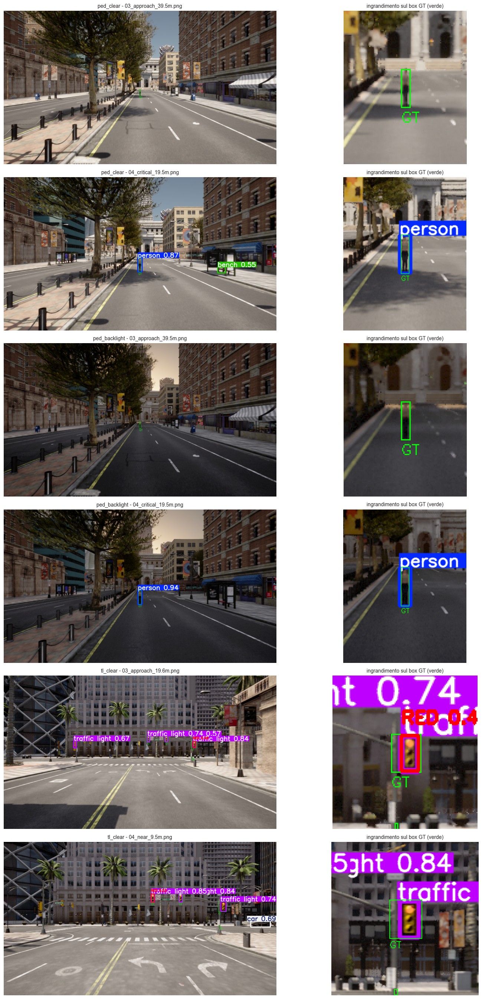

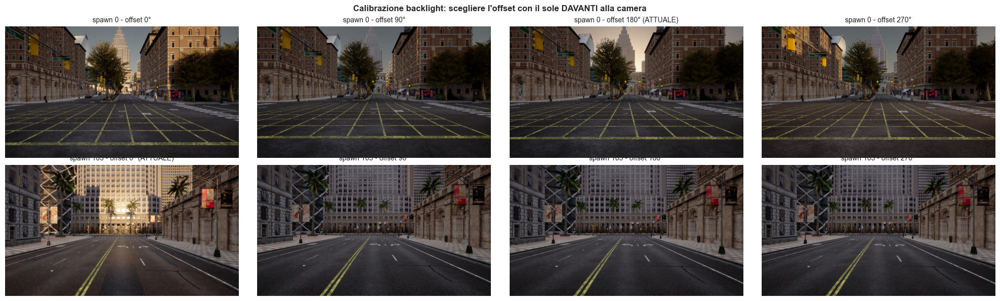


Report e immagini salvati in: smoke_test_20261016_150710


In [72]:
# SMOKE TEST: run brevi + controlli automatici + immagini da verificare a occhio
import re

SMOKE_DIR = f"smoke_test_{datetime.now():%Y%m%d_%H%M%S}"
os.makedirs(SMOKE_DIR, exist_ok=True)


def capture_sun_offsets(world, spawn_index, offsets=(0, 90, 180, 270), altitude=8.0, settle_ticks=5):
    """Frame della camera dell'ego (fermo allo spawn) con il sole a vari azimut relativi al suo yaw."""
    original_settings = enable_sync_mode(world)
    ego = camera = None
    frames = {}
    try:
        spawn = world.get_map().get_spawn_points()[spawn_index]
        ego = world.spawn_actor(world.get_blueprint_library().find('vehicle.tesla.model3'), spawn)
        camera = spawn_rgb_camera(world, ego)
        image_queue = queue.Queue()
        camera.listen(image_queue.put)
        for offset in offsets:
            params = weather_params('clear')
            params.update(sun_azimuth_angle=(spawn.rotation.yaw + offset) % 360.0, sun_altitude_angle=altitude)
            world.set_weather(carla.WeatherParameters(**params))
            for _ in range(settle_ticks):
                rgb, _, _ = tick_and_get_frame(world, image_queue)
            frames[offset] = rgb
    finally:
        if camera is not None:
            camera.stop()
            camera.destroy()
        if ego is not None:
            ego.destroy()
        world.tick()
        world.apply_settings(original_settings)
    return frames


# --- 1. Run brevi (cartelle dei sample deviate su SMOKE_DIR, poi ripristinate) ---
_saved_dirs = {k: globals().get(k) for k in ('SAMPLES_DIR', 'TL_SAMPLES_DIR')}
SAMPLES_DIR = os.path.join(SMOKE_DIR, 'detection_samples')
TL_SAMPLES_DIR = os.path.join(SMOKE_DIR, 'scenario2_traffic_light', 'detection_samples')
smoke_runs = {}
try:
    for w in ('clear', 'backlight'):
        smoke_runs[f'ped_{w}'] = (run_condition(world, model, 'SMOKE', w, 'none', 0), SAMPLES_DIR, f'{w}_none0')
    smoke_runs['tl_clear'] = (run_condition_tl(world, model, 'SMOKE', 'clear', 'none', 0), TL_SAMPLES_DIR, 'tl_clear_none0')
finally:
    for k, v in _saved_dirs.items():
        if v is None:
            globals().pop(k, None)
        else:
            globals()[k] = v

# --- 2. Controlli automatici ---
smoke_checks = []

def smoke_check(name, ok, detail=''):
    smoke_checks.append({'controllo': name, 'esito': 'PASS' if ok else 'FAIL', 'dettaglio': detail})

for name, ((row, frames), _, _) in smoke_runs.items():
    fdf = pd.DataFrame(frames)
    smoke_check(f'{name}: run completato', row['status'] == 'ok' and len(fdf) > 0,
                f"status={row['status']}, frame={len(fdf)}")
    if row['status'] != 'ok' or fdf.empty:
        continue
    smoke_check(f'{name}: meteo applicato', row.get('weather_ok') is True)
    steps = sorted(float(x) for x in fdf['elapsed_s'].diff().dropna().round(3).unique())
    smoke_check(f'{name}: passo tempo simulato', steps == [round(FIXED_DELTA_S, 3)], f"passi trovati: {steps[:5]}")
    ramp_frames = int(np.ceil(EGO_SPEED_MPS / (EGO_ACCEL_MPS2 * FIXED_DELTA_S)))
    speeds = fdf['speed_mps'].iloc[ramp_frames + 5:]
    speed_err = (speeds - EGO_SPEED_MPS).abs().max() / EGO_SPEED_MPS if len(speeds) else 1.0
    smoke_check(f'{name}: velocità costante dopo la rampa', speed_err < 0.05,
                f"{speeds.min() * 3.6:.1f}-{speeds.max() * 3.6:.1f} km/h dal frame {ramp_frames + 5} "
                f"(attesa {EGO_SPEED_KMH:.0f})")
    max_lat = fdf['lateral_offset_m'].abs().max()
    max_yaw = fdf['heading_change_deg'].abs().max()
    smoke_check(f'{name}: nessuno sbandamento', max_lat <= 0.3 and max_yaw <= 2.0,
                f"deriva laterale max {max_lat:.2f} m, variazione direzione max {max_yaw:.2f}°")
    smoke_check(f'{name}: target visibile', row['gt_visible_frames'] > 0, f"{row['gt_visible_frames']} frame")
    near_m = 25.0 if name.startswith('ped') else 20.0   # semaforo: m dalla linea d'arresto
    near = fdf[(fdf['gt_visible'] == 1) & (fdf['distance_m'] <= near_m)]
    aligned = float((near['target_iou'] > 0).mean()) if len(near) else 0.0
    iou_med = near.loc[near['target_iou'] > 0, 'target_iou'].median() if aligned > 0 else float('nan')
    smoke_check(f'{name}: ground truth allineata', aligned >= 0.5,
                f"{aligned:.0%} dei {len(near)} frame entro {near_m:.0f} m con una detection sul box GT "
                f"(IoU mediana {iou_med:.2f})")

(tl_row, _), _, _ = smoke_runs['tl_clear']
if tl_row['status'] == 'ok':
    smoke_check('tl_clear: semaforo rosso classificato rosso', tl_row.get('state_accuracy', 0) >= 0.8,
                f"state_accuracy={tl_row.get('state_accuracy')}")
    lane_id = tl_row.get('lane_tl_id')
    smoke_check('tl_clear: target = semaforo della corsia', lane_id in (None, tl_row.get('target_tl_id')),
                f"target ID={tl_row.get('target_tl_id')}, semaforo dell'ego secondo CARLA: "
                f"{lane_id if lane_id is not None else 'non disponibile'}, "
                f"linea d'arresto a {tl_row.get('start_distance_m')} m")

smoke_df = pd.DataFrame(smoke_checks)
print("\n" + "=" * 70)
print("  SMOKE TEST: controlli automatici")
print("=" * 70)
print(smoke_df.to_string(index=False))
n_fail = int((smoke_df['esito'] == 'FAIL').sum())
print(f"\n{'TUTTI I CONTROLLI PASS' if n_fail == 0 else f'{n_fail} CONTROLLI FAIL: non lanciare il benchmark completo'}")

# --- 3. Controllo visivo della ground truth (box verde) ---
panels = []
for name, ((row, frames), samples_dir, run_label) in smoke_runs.items():
    fdf = pd.DataFrame(frames)
    run_dir = os.path.join(samples_dir, run_label)
    if fdf.empty or not os.path.isdir(run_dir):
        continue
    for fname in sorted(os.listdir(run_dir)):
        m = re.match(r'(03_approach|04_\w+?)_(\d+\.\d)m\.png$', fname)
        if not m:
            continue
        vis = fdf[fdf['gt_visible'] == 1]
        if vis.empty:
            continue
        frame_row = vis.iloc[(vis['distance_m'] - float(m.group(2))).abs().argmin()]
        image = np.array(Image.open(os.path.join(run_dir, fname)).convert('RGB'))
        panels.append((f"{name} - {fname}", image, gt_zoom(image, frame_row)))

if panels:
    fig, axes = plt.subplots(len(panels), 2, figsize=(16, 4.5 * len(panels)),
                             gridspec_kw={'width_ratios': [2, 1]}, squeeze=False)
    for (title, image, zoom), (ax_full, ax_zoom) in zip(panels, axes):
        ax_full.imshow(image); ax_full.set_title(title, fontsize=10); ax_full.axis('off')
        ax_zoom.imshow(zoom); ax_zoom.set_title('ingrandimento sul box GT (verde)', fontsize=10); ax_zoom.axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(SMOKE_DIR, 'gt_check.png'), dpi=110, bbox_inches='tight')
    plt.show()

# --- 4. Calibrazione backlight: dove si trova il sole al variare dell'offset di azimut ---
sun_offsets = (0, 90, 180, 270)
sun_frames = {sp: capture_sun_offsets(world, sp, sun_offsets) for sp in (0, 103)}
fig, axes = plt.subplots(2, len(sun_offsets), figsize=(20, 6))
for r, (sp, frames) in enumerate(sun_frames.items()):
    for c, offset in enumerate(sun_offsets):
        current = ' (ATTUALE)' if offset == backlight_offset(sp) else ''
        axes[r, c].imshow(frames[offset])
        axes[r, c].set_title(f"spawn {sp} - offset {offset}°{current}", fontsize=10)
        axes[r, c].axis('off')
plt.suptitle("Calibrazione backlight: scegliere l'offset con il sole DAVANTI alla camera", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(SMOKE_DIR, 'backlight_calibration.png'), dpi=110, bbox_inches='tight')
plt.show()

# --- 5. Report su file ---
with open(os.path.join(SMOKE_DIR, 'smoke_report.json'), 'w', encoding='utf-8') as f:
    json.dump({'checks': smoke_checks,
               'runs': {name: row for name, ((row, _), _, _) in smoke_runs.items()}},
              f, indent=2, ensure_ascii=False, default=str)
print(f"\nReport e immagini salvati in: {SMOKE_DIR}")


## 11. Esecuzione Benchmark Scenario 1 (Pedone)

Questa cella esegue tutti i test configurati in `TESTS` (Sezione 7) per lo Scenario 1. Può richiedere diversi minuti.

**Prima di lanciarla**, eseguire lo smoke test (Sezione 10) e controllare che tutti i controlli risultino `PASS`.

Per ogni condizione viene anche valutato il **modulo FCW** (Sezione 8.1). Insieme ai CSV viene salvato `config.json` con la configurazione completa e il meteo effettivamente applicato in ogni run.


In [73]:
# Genera batch ID univoco
batch_id = datetime.now().strftime('%Y%m%d_%H%M%S')
all_summary_rows = []
all_frame_rows = []
fcw_results = {}

print(f"Benchmark avviato | batch={batch_id}")
print(f"   Test totali: {len(TESTS)}")
print("-" * 60)

for idx, test in enumerate(TESTS, 1):
    print(f"\n[{idx}/{len(TESTS)}] Test in corso...")
    
    summary_row, frame_rows = run_condition(
        world=world,
        model=model,
        batch_id=batch_id,
        weather=test['weather'],
        corruption=test['corruption'],
        severity=test['severity'],
    )
    
    # Valutazione FCW su frame_rows (pedone confermato / falso positivo nel percorso)
    fcw_summary = evaluate_warning(frame_rows, 'detected', 'fp_in_path', 'fcw_')
    summary_row.update(fcw_summary)
    fcw_results[summary_row['run_label']] = fcw_summary
    
    all_summary_rows.append(summary_row)
    all_frame_rows.extend(frame_rows)

# Salva risultati
SUMMARY_FIELDS = [
    'batch_id', 'run_label', 'weather', 'corruption', 'severity',
    'total_frames', 'detection_frames', 'detection_rate',
    'first_detection_distance_m', 'first_detection_elapsed_s',
    'warning_delay_s', 'min_distance_m',
    'miss_rate', 'gt_visible_frames', 'false_negatives',
    'false_positive_count', 'precision', 'fp_per_frame',
    'critical_zone_frames', 'critical_zone_misses',
    'fcw_warnings_issued', 'fcw_true_positives', 'fcw_missed_warnings',
    'fcw_false_alarms', 'fcw_false_alarm_events', 'fcw_precision', 'fcw_recall',
    'fcw_first_warning_distance_m', 'fcw_ttc_at_warning_s', 'fcw_warning_delay_s',
    'fcw_stopping_distance_m', 'fcw_can_stop', 'fcw_warning_zone_frames',
    'weather_ok', 'weather_params',
    'status',
]

FRAME_FIELDS = [
    'batch_id', 'run_label', 'weather', 'corruption', 'severity',
    'frame_index', 'elapsed_s', 'distance_m',
    'persons_detected', 'max_confidence', 'detected', 'in_critical_zone',
    'gt_visible', 'gt_x1', 'gt_y1', 'gt_x2', 'gt_y2', 'gt_height_px',
    'target_iou', 'tp', 'fn', 'fp', 'fp_confs', 'fp_in_path',
    'speed_mps', 'gap_m', 'ttc_s', 'lateral_offset_m', 'heading_change_deg',
]

append_csv_rows(RUN_SUMMARY_PATH, SUMMARY_FIELDS, all_summary_rows)
append_csv_rows(FRAME_LOG_PATH, FRAME_FIELDS, all_frame_rows)
save_benchmark_config(os.path.join(RESULTS_DIR, 'config.json'), 'pedestrian', all_summary_rows)

print("\n" + "=" * 60)
print(f"Benchmark completato!")
print(f"   Risultati salvati: {RUN_SUMMARY_PATH}")
print(f"   Frame log salvato: {FRAME_LOG_PATH}")
print(f"   Sample annotate: {SAMPLES_DIR}")


Benchmark avviato | batch=20261016_151018
   Test totali: 10
------------------------------------------------------------

[1/10] Test in corso...

  Running: clear_none0
  Modalita' sincrona: True, passo fisso 0.05 s
  BG Vehicle (Audi A2) spawnato con successo! Road ID: 20, Lane ID: 4
  Meteo verificato sul server: clear
  Prima detection PERSON: 28.9m (conf=0.59, IoU=0.73)
  Veicolo arrivato a destinazione (<3m), stop.
  Risultato clear_none0: detection_rate (recall)=24.44% (44/180 frame con pedone visibile), precision=93.62%
     Sample salvati: 7
     Classi rilevate (conf>=0.55): {'traffic light': 335, 'car': 109, 'person': 47, 'bench': 3, 'clock': 1}
     Warning delay: 0.0s
     Miss rate (zona critica): 4.35% (2/46)
     Falsi positivi 'person': 3 (0.016 per frame)

[2/10] Test in corso...

  Running: rain_none0
  Modalita' sincrona: True, passo fisso 0.05 s
  BG Vehicle (Audi A2) spawnato con successo! Road ID: 20, Lane ID: 4
  Meteo verificato sul server: rain
  Prima detect

## 12. Esecuzione Benchmark Scenario 2 (Semaforo)

Esegue gli stessi `TESTS` dello Scenario 1 sul semaforo. Per ogni condizione viene valutato il **Red Light Warning** (Sezione 8.1, metriche `rlw_*`). Insieme ai CSV viene salvato `config.json`.

In [74]:
# === BATCH RUNNER SCENARIO 2 ===

# Directory dedicate per Scenario 2 (zero interferenza con Scenario 1)
TL_BASE_DIR = os.path.join(BASE_OUTPUT_DIR, 'scenario2_traffic_light')
TL_RESULTS_DIR = os.path.join(TL_BASE_DIR, 'results')
TL_SAMPLES_DIR = os.path.join(TL_BASE_DIR, 'detection_samples')
TL_PLOTS_DIR = os.path.join(TL_BASE_DIR, 'plots')

os.makedirs(TL_RESULTS_DIR, exist_ok=True)
os.makedirs(TL_SAMPLES_DIR, exist_ok=True)
os.makedirs(TL_PLOTS_DIR, exist_ok=True)

print(f"\n{'='*60}")
print("AVVIO BATCH: SCENARIO 2 (TRAFFIC LIGHT DETECTION)")
print(f"Cartella output dedicata: {TL_BASE_DIR}")
print(f"{'='*60}")

tl_batch_id = f"TL_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
tl_summary_rows = []
tl_frame_rows = []

for idx, test in enumerate(TESTS, 1):
    print(f"\n[{idx}/{len(TESTS)}] TL Test in corso...")
    
    summary_row, frame_rows = run_condition_tl(
        world=world,
        model=model,
        batch_id=tl_batch_id,
        weather=test['weather'],
        corruption=test['corruption'],
        severity=test['severity'],
    )
    
    # Red light warning: semaforo confermato e classificato rosso / falso positivo rosso
    summary_row.update(evaluate_warning(frame_rows, 'rlw_positive', 'fp_red', 'rlw_'))
    tl_summary_rows.append(summary_row)
    tl_frame_rows.extend(frame_rows)

# Salva risultati nella cartella dedicata di Scenario 2
tl_summary_df = pd.DataFrame(tl_summary_rows)
tl_summary_df.to_csv(os.path.join(TL_RESULTS_DIR, 'run_summary.csv'), index=False)

tl_frame_df = pd.DataFrame(tl_frame_rows)
tl_frame_df.to_csv(os.path.join(TL_RESULTS_DIR, 'frame_metrics.csv'), index=False)
save_benchmark_config(os.path.join(TL_RESULTS_DIR, 'config.json'), 'traffic_light', tl_summary_rows)

print("\n✅ Scenario 2 completato!")
print(f"   Risultati salvati in: {TL_RESULTS_DIR}")
print(f"   Campioni visivi in:   {TL_SAMPLES_DIR}")



AVVIO BATCH: SCENARIO 2 (TRAFFIC LIGHT DETECTION)
Cartella output dedicata: output_batch_20261016_150514\scenario2_traffic_light

[1/10] TL Test in corso...

  Running: tl_clear_none0
  Modalita' sincrona: True, passo fisso 0.05 s
  AVVISO: strada non dritta 5 m dietro lo spawn: uso lo spawn originale
  Semaforo target (regola la corsia dell'ego): ID=12, linea d'arresto a 40 m dallo spawn
  Meteo verificato sul server: clear
  Ground truth: 54 lanterne di semafori vicini, 4 del semaforo target
  Linea d'arresto a 38.4 m dal paraurti
  Prima detection SEMAFORO: 38.4m (conf=0.57, IoU=0.53)
  Veicolo arrivato alla linea d'arresto (0.0 m) -> fine run
  Risultato tl_clear_none0: detection_rate (recall)=61.95% (70/113 frame con semaforo visibile), precision=98.59%
     Sample salvati: 6
     Classi rilevate (conf>=0.55): {'traffic light': 192, 'car': 10, 'fire hydrant': 3}
     Prima detection semaforo: 38.4m
     Miss rate (zona critica): 0.00% (0/56)
     Falsi positivi 'traffic light': 1

## 13. Analisi Risultati

### 13.1 Caricamento e tabella riassuntiva

Vengono caricati **solo i batch nel formato attuale**, cioè le cartelle `output_batch_*` che contengono `config.json`; i batch delle versioni precedenti vengono ignorati automaticamente. Se ci sono più batch validi, le metriche sono la media tra i batch (`n_run`), con la deviazione standard della recall.

**Definizione di collasso** (uguale per entrambi gli scenari):

| Esito | Criterio |
|---|---|
| **COLLASSO** | il warning arriva troppo tardi per fermarsi (o non arriva), **oppure** la recall in zona critica scende sotto il 50% di quella in clear |
| **DEGRADATO** | la recall in zona critica scende sotto l'80% del clear, **oppure** il warning arriva più di 0.5 s dopo rispetto al clear (TTC più basso) |
| **OK** | nessuno dei casi precedenti |

La **recall in zona critica** è la frazione dei frame con target visibile, entro la zona critica (30 m dal pedone; per il semaforo la zona di warning, 2.5 s alla velocità di crociera: ~28 m dalla linea d'arresto a 40 km/h), in cui il target è stato rilevato. Il "troppo tardi per fermarsi" usa `can_stop` del modulo di warning (Sezione 8.1).

La tabella viene salvata anche in `plots/summary_<scenario>.csv` e `.md` per il report.


In [75]:
# CARICAMENTO RISULTATI E TABELLA RIASSUNTIVA
COLLAPSE_RECALL_FRAC = 0.5   # COLLASSO se la recall in zona critica < 50% di quella in clear
DEGRADED_RECALL_FRAC = 0.8   # DEGRADATO se < 80%
DEGRADED_TTC_DROP_S = 0.5    # DEGRADATO se il warning arriva > 0.5 s piu' tardi (TTC) rispetto al clear

SCENARIOS = {
    'ped': {'name': 'Scenario 1 - Pedone (FCW)', 'results': 'results', 'samples': 'detection_samples',
            'prefix': 'fcw_', 'side_sample': '04_critical'},
    'tl': {'name': 'Scenario 2 - Semaforo (Red Light Warning)',
           'results': os.path.join('scenario2_traffic_light', 'results'),
           'samples': os.path.join('scenario2_traffic_light', 'detection_samples'),
           'prefix': 'rlw_', 'side_sample': '03_approach'},
}
SEVERITY_NAMES = {1: 'mild', 2: 'severe'}
VERDICT_COLORS = {'OK': '#2e7d32', 'DEGRADATO': '#f9a825', 'COLLASSO': '#c62828'}


def condition_label(weather, corruption, severity):
    """Nome leggibile della condizione: 'fog', 'blur mild', 'rain + blur severe', ..."""
    weather = weather.replace('_', ' ')   # 'fog_severe' -> 'fog severe'
    if corruption == 'none':
        return weather
    name = f"{corruption.replace('_', ' ')} {SEVERITY_NAMES.get(int(severity), f's{int(severity)}')}"
    return name if weather == 'clear' else f"{weather} + {name}"


def load_scenario(key):
    """Carica summary e frame di tutti i batch validi (con config.json) di uno scenario."""
    cfg = SCENARIOS[key]
    batches = sorted(d for d in glob.glob('output_batch_*')
                     if os.path.exists(os.path.join(d, cfg['results'], 'config.json')))
    if not batches:
        return None
    summaries, frames = [], []
    for d in batches:
        s = pd.read_csv(os.path.join(d, cfg['results'], 'run_summary.csv'))
        s['batch_dir'] = d
        summaries.append(s)
        f_path = os.path.join(d, cfg['results'], 'frame_metrics.csv')
        if os.path.exists(f_path):
            f = pd.read_csv(f_path)
            f['batch_dir'] = d
            frames.append(f)
    summary = pd.concat(summaries, ignore_index=True)
    frames = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    for df in (summary, frames):
        if len(df):
            df['condition'] = [condition_label(w, c, s) for w, c, s in zip(df['weather'], df['corruption'], df['severity'])]
    with open(os.path.join(batches[-1], cfg['results'], 'config.json'), encoding='utf-8') as fh:
        config = json.load(fh)
    return {'summary': summary, 'frames': frames, 'batches': batches, 'latest': batches[-1], 'config': config}


def aggregate(summary, prefix):
    """Una riga per condizione (media tra i batch), nell'ordine dei TESTS."""
    ok = summary[summary['status'] == 'ok'].copy()
    ok['critical_recall'] = np.where(ok['critical_zone_frames'] > 0, 1 - ok['miss_rate'], np.nan)
    ok['can_stop_num'] = ok[prefix + 'can_stop'].map({True: 1.0, False: 0.0, 'True': 1.0, 'False': 0.0})
    for col in (prefix + 'ttc_at_warning_s', prefix + 'warning_delay_s', 'first_detection_distance_m'):
        ok[col] = pd.to_numeric(ok[col], errors='coerce')
    named = {
        'n_run': ('batch_dir', 'nunique'),
        'critical_recall': ('critical_recall', 'mean'),
        'critical_recall_std': ('critical_recall', 'std'),
        'recall': ('detection_rate', 'mean'),
        'first_detection_m': ('first_detection_distance_m', 'mean'),
        'precision': ('precision', 'mean'),
        'fp_per_frame': ('fp_per_frame', 'mean'),
        'ttc_at_warning_s': (prefix + 'ttc_at_warning_s', 'mean'),
        'warning_delay_s': (prefix + 'warning_delay_s', 'mean'),
        'can_stop': ('can_stop_num', 'mean'),
    }
    if 'state_accuracy' in ok:
        named['state_accuracy'] = ('state_accuracy', 'mean')
    order = list(dict.fromkeys(ok['condition']))
    return ok.groupby('condition', sort=False).agg(**named).reindex(order)


def verdict(row, ref):
    """Esito (OK / DEGRADATO / COLLASSO) e motivo, rispetto alla riga di riferimento (clear)."""
    if not row['can_stop'] >= 0.5:
        return 'COLLASSO', ('warning troppo tardi per fermarsi' if pd.notna(row['ttc_at_warning_s'])
                            else 'nessun warning')
    if ref is None:
        return 'OK', ''
    if ref['critical_recall'] > 0:
        ratio = row['critical_recall'] / ref['critical_recall']
        if ratio < COLLAPSE_RECALL_FRAC:
            return 'COLLASSO', f'recall zona critica al {ratio:.0%} del clear'
        if ratio < DEGRADED_RECALL_FRAC:
            return 'DEGRADATO', f'recall zona critica al {ratio:.0%} del clear'
    ttc_drop = ref['ttc_at_warning_s'] - row['ttc_at_warning_s']
    if ttc_drop > DEGRADED_TTC_DROP_S:
        return 'DEGRADATO', f'warning {ttc_drop:.1f} s piu\' tardi del clear'
    return 'OK', ''


RESULTS = {}
for key, cfg in SCENARIOS.items():
    res = load_scenario(key)
    if res is None:
        print(f"{cfg['name']}: nessun batch valido trovato (eseguire le Sezioni 11/12)")
        continue
    agg = aggregate(res['summary'], cfg['prefix'])
    ref = agg.loc['clear'] if 'clear' in agg.index else None
    verdicts = [verdict(row, ref) for _, row in agg.iterrows()]
    agg['esito'] = [v[0] for v in verdicts]
    agg['motivo'] = [v[1] for v in verdicts]
    res['agg'] = agg
    res['plots_dir'] = os.path.join(res['latest'], 'plots')
    os.makedirs(res['plots_dir'], exist_ok=True)
    RESULTS[key] = res

    pct = lambda v: f'{v:.0%}' if pd.notna(v) else '-'
    table = pd.DataFrame({
        'Condizione': agg.index,
        'Recall zona critica': agg['critical_recall'].map(pct),
        'Recall totale': agg['recall'].map(pct),
        'Prima detection (m)': agg['first_detection_m'].map(lambda v: f'{v:.1f}' if pd.notna(v) else '-'),
        'Precision': agg['precision'].map(pct),
        'FP/frame': agg['fp_per_frame'].map('{:.3f}'.format),
        'TTC al warning (s)': agg['ttc_at_warning_s'].map(lambda v: f'{v:.2f}' if pd.notna(v) else 'nessuno'),
        'Ritardo warning (s)': agg['warning_delay_s'].map(lambda v: f'{v:.2f}' if pd.notna(v) else '-'),
        'Si ferma in tempo': agg['can_stop'].map(lambda v: 'si' if v >= 0.5 else 'NO'),
        'Esito': agg['esito'],
        'Motivo': agg['motivo'],
    })
    if 'state_accuracy' in agg:
        table.insert(5, 'Colore corretto', agg['state_accuracy'].map(pct).values)
    res['table'] = table

    print('=' * 100)
    print(f"  {cfg['name']}  |  batch: {', '.join(res['batches'])}  |  run per condizione: {int(agg['n_run'].max())}")
    print('=' * 100)
    print(table.to_string(index=False))
    print()
    table.to_csv(os.path.join(res['plots_dir'], f'summary_{key}.csv'), index=False)
    try:
        with open(os.path.join(res['plots_dir'], f'summary_{key}.md'), 'w', encoding='utf-8') as fh:
            fh.write(table.to_markdown(index=False))
    except ImportError:
        pass  # to_markdown richiede il pacchetto 'tabulate'


  Scenario 1 - Pedone (FCW)  |  batch: output_batch_20261016_142109, output_batch_20261016_150514  |  run per condizione: 2
  Condizione Recall zona critica Recall totale Prima detection (m) Precision FP/frame TTC al warning (s) Ritardo warning (s) Si ferma in tempo    Esito                            Motivo
       clear                 96%           24%                28.9       94%    0.016               2.24                0.25                si       OK                                  
        rain                 99%           26%                30.3       93%    0.019               2.39                0.10                si       OK                                  
         fog                 98%           25%                28.9       92%    0.022               2.29                0.20                si       OK                                  
       night                100%           26%                29.5       92%    0.022               2.34                0.15        

### 13.2 Quando collassa la baseline

Per ogni scenario, due grafici con i colori dell'esito (verde OK, giallo DEGRADATO, rosso COLLASSO):

- **Sinistra, recall in zona critica**: quanto spesso il target viene rilevato quando è vicino. La linea tratteggiata rossa è la soglia di collasso (50% della recall in clear).
- **Destra, TTC al primo warning**: quanto tempo prima dell'impatto (o della linea d'arresto) arriva il warning. La linea tratteggiata rossa è il **TTC minimo per fermarsi** (tempo di reazione + frenata): una barra sotto questa linea significa che il guidatore, anche reagendo subito, non riesce a fermarsi. La linea grigia è la soglia a cui il warning viene emesso quando la percezione è perfetta.


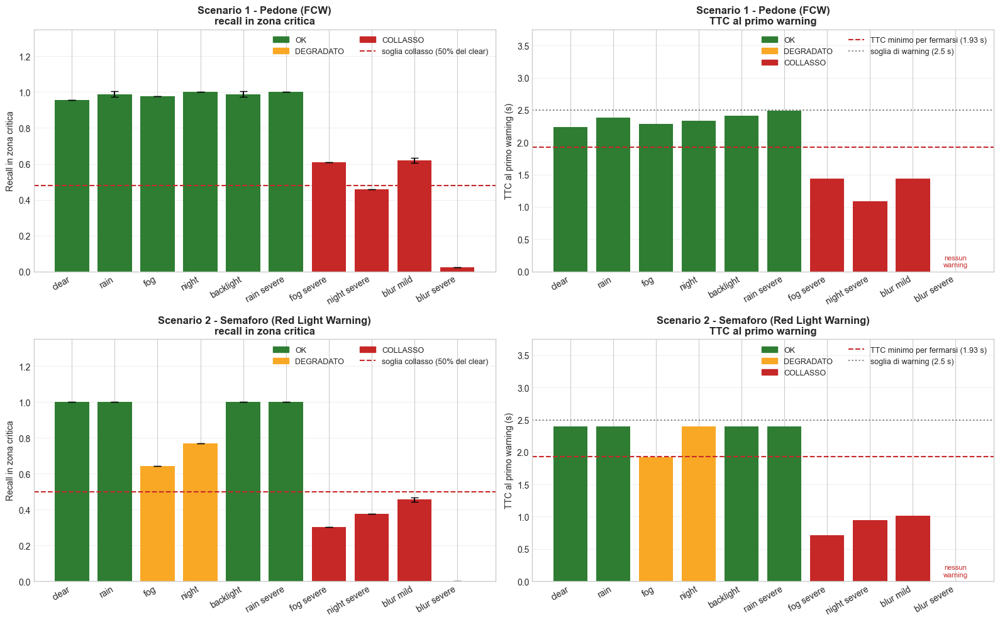

In [76]:
# QUANDO COLLASSA: recall in zona critica e TTC al warning per condizione
def warning_limits(config):
    """(soglia TTC di warning, TTC minimo per fermarsi) dalla configurazione del batch."""
    w, m = config['warning'], config['motion']
    speed = m['ego_speed_kmh'] / 3.6
    return w['ttc_warning_s'], w['reaction_s'] + speed / (2.0 * w['decel_mps2'])


def verdict_legend(ax, extra=()):
    handles = [mpatches.Patch(color=c, label=v) for v, c in VERDICT_COLORS.items()]
    ax.legend(handles=handles + list(extra), fontsize=9, loc='upper right', ncol=2)


if RESULTS:
    fig, axes = plt.subplots(len(RESULTS), 2, figsize=(16, 5 * len(RESULTS)), squeeze=False)
    for (key, res), (ax_rec, ax_ttc) in zip(RESULTS.items(), axes):
        agg, cfg = res['agg'], SCENARIOS[key]
        x = np.arange(len(agg))
        colors = [VERDICT_COLORS[v] for v in agg['esito']]
        ttc_warn, ttc_stop = warning_limits(res['config'])

        # Recall in zona critica
        yerr = agg['critical_recall_std'] if agg['n_run'].max() > 1 else None
        ax_rec.bar(x, agg['critical_recall'], color=colors, yerr=yerr, capsize=4)
        extra = []
        if 'clear' in agg.index:
            thr = COLLAPSE_RECALL_FRAC * agg.loc['clear', 'critical_recall']
            extra.append(ax_rec.axhline(thr, color='#c62828', ls='--', lw=1.5,
                                        label=f'soglia collasso ({COLLAPSE_RECALL_FRAC:.0%} del clear)'))
        ax_rec.set_ylim(0, 1.35)  # spazio in alto per la legenda
        ax_rec.set_ylabel('Recall in zona critica')
        ax_rec.set_title(f"{cfg['name']}\nrecall in zona critica", fontweight='bold')
        verdict_legend(ax_rec, extra)

        # TTC al primo warning (0 = nessun warning)
        ttc = agg['ttc_at_warning_s']
        ax_ttc.bar(x, ttc.fillna(0), color=colors)
        for xi, v in zip(x, ttc):
            if pd.isna(v):
                ax_ttc.text(xi, 0.05, 'nessun\nwarning', ha='center', va='bottom', fontsize=8, color='#c62828')
        lines = [ax_ttc.axhline(ttc_stop, color='#c62828', ls='--', lw=1.5,
                                label=f'TTC minimo per fermarsi ({ttc_stop:.2f} s)'),
                 ax_ttc.axhline(ttc_warn, color='gray', ls=':', lw=1.5,
                                label=f'soglia di warning ({ttc_warn:.1f} s)')]
        ax_ttc.set_ylim(0, ttc_warn * 1.5)  # spazio in alto per la legenda
        ax_ttc.set_ylabel('TTC al primo warning (s)')
        ax_ttc.set_title(f"{cfg['name']}\nTTC al primo warning", fontweight='bold')
        verdict_legend(ax_ttc, lines)

        for ax in (ax_rec, ax_ttc):
            ax.set_xticks(x)
            ax.set_xticklabels(agg.index, rotation=30, ha='right')
            ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    for plots_dir in {r['plots_dir'] for r in RESULTS.values()}:
        plt.savefig(os.path.join(plots_dir, 'collapse_overview.png'), dpi=150, bbox_inches='tight')
    plt.show()


### 13.3 Recall in funzione della distanza

Per ogni condizione, la frazione di frame (con target visibile) in cui il target viene rilevato, a intervalli di 5 m. Mostra **da quale distanza** il sistema inizia a vedere il target: una curva spostata verso destra significa rilevamento più precoce. L'asse X è invertito (il veicolo si avvicina da sinistra verso destra) e l'area rossa è la zona critica.


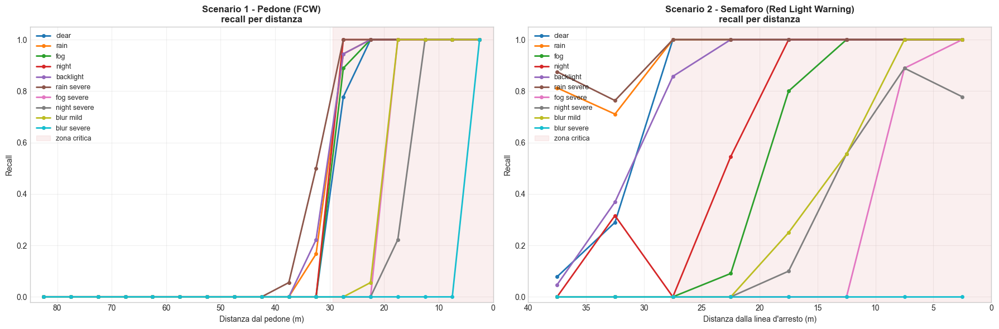

In [77]:
# RECALL IN FUNZIONE DELLA DISTANZA (bin da 5 m)
if RESULTS:
    fig, axes = plt.subplots(1, len(RESULTS), figsize=(9 * len(RESULTS), 6), squeeze=False)
    for (key, res), ax in zip(RESULTS.items(), axes[0]):
        frames = res['frames']
        if frames.empty:
            continue
        vis = frames[frames['gt_visible'] == 1].copy()
        max_d = float(np.ceil(vis['distance_m'].max() / 5.0) * 5.0)
        crit_m = vis.loc[vis['in_critical_zone'] == 1, 'distance_m'].max()  # limite della zona critica
        vis['bin'] = pd.cut(vis['distance_m'], bins=np.arange(0, max_d + 5, 5), right=False)
        cmap = plt.get_cmap('tab10')
        for i, cond in enumerate(res['agg'].index):
            curve = vis[vis['condition'] == cond].groupby('bin', observed=True)['tp'].mean()
            ax.plot([b.mid for b in curve.index], curve.values, marker='o', ms=4, lw=2,
                    color=cmap(i % 10), label=cond)
        if not pd.isna(crit_m):
            ax.axvspan(0, crit_m, color='#c62828', alpha=0.07, label='zona critica')
        ax.set_xlim(max_d, 0)
        ax.set_ylim(-0.02, 1.05)
        ax.set_xlabel("Distanza dalla linea d'arresto (m)" if key == 'tl' else 'Distanza dal pedone (m)')
        ax.set_ylabel('Recall')
        ax.set_title(f"{SCENARIOS[key]['name']}\nrecall per distanza", fontweight='bold')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9, loc='upper left')
    plt.tight_layout()
    for plots_dir in {r['plots_dir'] for r in RESULTS.values()}:
        plt.savefig(os.path.join(plots_dir, 'recall_vs_distance.png'), dpi=150, bbox_inches='tight')
    plt.show()


### 13.4 Corruzione visiva: blur mild e severe

Andamento delle due metriche principali passando da nessuna corruzione (clear) a blur mild e blur severe, per entrambi gli scenari. Il passaggio in cui la curva scende sotto la soglia di collasso indica la **soglia di fallimento** rispetto al blur.


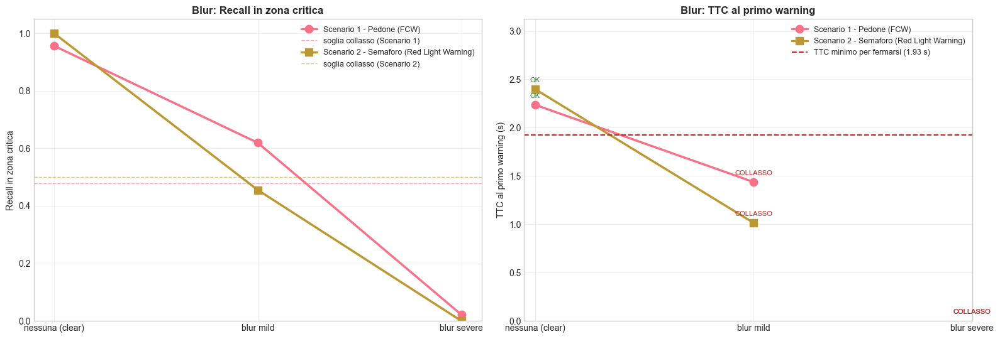

In [78]:
# BLUR: clear -> mild -> severe
BLUR_STEPS = ['clear', 'blur mild', 'blur severe']

blur_results = {k: r for k, r in RESULTS.items() if all(s in r['agg'].index for s in BLUR_STEPS)}
if blur_results:
    fig, (ax_rec, ax_ttc) = plt.subplots(1, 2, figsize=(16, 5.5))
    markers = {'ped': 'o', 'tl': 's'}
    x = np.arange(len(BLUR_STEPS))
    for key, res in blur_results.items():
        rows = res['agg'].loc[BLUR_STEPS]
        name = SCENARIOS[key]['name']
        ax_rec.plot(x, rows['critical_recall'], marker=markers[key], ms=9, lw=2.5, label=name)
        ax_rec.axhline(COLLAPSE_RECALL_FRAC * rows.loc['clear', 'critical_recall'], ls='--', lw=1, alpha=0.6,
                       color=ax_rec.lines[-1].get_color(), label=f'soglia collasso ({name.split(" - ")[0]})')
        ax_ttc.plot(x, rows['ttc_at_warning_s'], marker=markers[key], ms=9, lw=2.5, label=name)
        for xi, (v, esito) in enumerate(zip(rows['ttc_at_warning_s'], rows['esito'])):
            ax_ttc.annotate(esito, (xi, 0 if pd.isna(v) else v), textcoords='offset points', xytext=(0, 8),
                            ha='center', fontsize=8, color=VERDICT_COLORS[esito])
    ttc_warn, ttc_stop = warning_limits(next(iter(blur_results.values()))['config'])
    ax_ttc.axhline(ttc_stop, color='#c62828', ls='--', lw=1.5, label=f'TTC minimo per fermarsi ({ttc_stop:.2f} s)')
    ax_rec.set_ylabel('Recall in zona critica')
    ax_rec.set_ylim(0, 1.05)
    ax_ttc.set_ylabel('TTC al primo warning (s)')
    ax_ttc.set_ylim(0, ttc_warn * 1.25)
    for ax, title in ((ax_rec, 'Recall in zona critica'), (ax_ttc, 'TTC al primo warning')):
        ax.set_xticks(x)
        ax.set_xticklabels(['nessuna (clear)', 'blur mild', 'blur severe'])
        ax.set_title(f'Blur: {title}', fontweight='bold')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=9)
    plt.tight_layout()
    for plots_dir in {r['plots_dir'] for r in blur_results.values()}:
        plt.savefig(os.path.join(plots_dir, 'blur_degradation.png'), dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Condizioni clear / blur mild / blur severe non presenti nei risultati")


## 14. Confronto Visuale Side-by-Side

Lo **stesso frame**, alla stessa distanza dal target, in tutte le condizioni: circa 20 m per il pedone, circa 42 m per il semaforo. Le traiettorie sono identiche in ogni run, quindi l'unica differenza tra le immagini è la condizione ambientale o la corruzione.

- **Riga superiore**: frame intero con le detection di YOLO (sopra soglia) e il box di ground truth in verde.
- **Riga inferiore**: ingrandimento attorno al target.

Il titolo riporta l'esito della condizione (Sezione 13.1). Risponde al requisito: *"Include at least one clean side-by-side comparison for rain, fog, night, and blur"*.


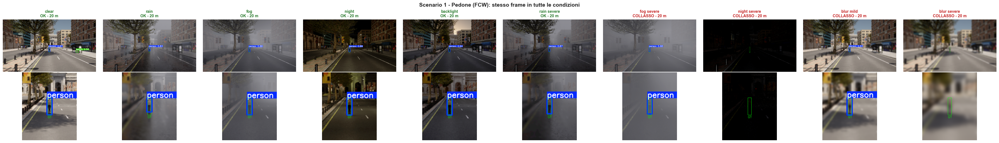

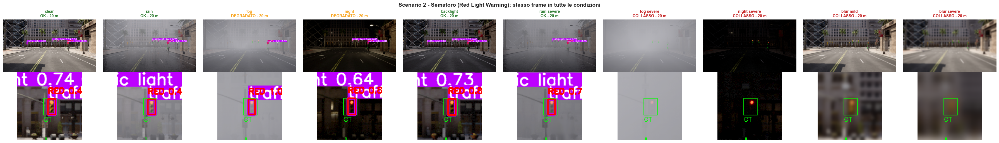

In [79]:
# SIDE-BY-SIDE: stesso frame (stessa distanza) in tutte le condizioni, dall'ultimo batch
import re


def sample_with_gt(res, run_label, prefix):
    """(immagine annotata, ingrandimento sul GT, distanza) del sample che inizia con prefix, o None."""
    run_dir = os.path.join(res['latest'], SCENARIOS[res['key']]['samples'], run_label)
    if not os.path.isdir(run_dir):
        return None
    for fname in sorted(os.listdir(run_dir)):
        m = re.match(re.escape(prefix) + r'.*?_(\d+\.\d)m', fname)
        if not m:
            continue
        image = np.array(Image.open(os.path.join(run_dir, fname)).convert('RGB'))
        frames = res['frames']
        vis = frames[(frames['batch_dir'] == res['latest']) & (frames['run_label'] == run_label)
                     & (frames['gt_visible'] == 1)]
        zoom = None
        if len(vis):
            row = vis.iloc[(vis['distance_m'] - float(m.group(1))).abs().argmin()]
            zoom = gt_zoom(image, row)
        return image, zoom, float(m.group(1))
    return None


for key, res in RESULTS.items():
    res['key'] = key
    latest = res['summary'][res['summary']['batch_dir'] == res['latest']]
    labels = dict(zip(latest['condition'], latest['run_label']))
    panels = []
    for cond in res['agg'].index:
        if cond in labels:
            found = sample_with_gt(res, labels[cond], SCENARIOS[key]['side_sample'])
            if found:
                panels.append((cond, res['agg'].loc[cond, 'esito']) + found)
    if not panels:
        print(f"{SCENARIOS[key]['name']}: nessun sample trovato in {res['latest']}")
        continue
    fig, axes = plt.subplots(2, len(panels), figsize=(3.6 * len(panels), 5.2), squeeze=False,
                             gridspec_kw={'height_ratios': [1, 1.3]})
    for c, (cond, esito, image, zoom, dist) in enumerate(panels):
        axes[0, c].imshow(image)
        axes[0, c].set_title(f"{cond}\n{esito} - {dist:.0f} m", fontsize=10, fontweight='bold',
                             color=VERDICT_COLORS[esito])
        if zoom is not None:
            axes[1, c].imshow(zoom)
        for ax in axes[:, c]:
            ax.axis('off')
    plt.suptitle(f"{SCENARIOS[key]['name']}: stesso frame in tutte le condizioni", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(res['plots_dir'], f'side_by_side_{key}.png'), dpi=150, bbox_inches='tight')
    plt.show()


## 15. Failure Cases

Un **failure case** è un frame in cui il target viene rilevato in clear ma **non** nella condizione considerata. Grazie alle traiettorie identiche, lo stesso indice di frame corrisponde alla stessa posizione del veicolo in tutte le condizioni, quindi il confronto è diretto.

- **Tabella**: per ogni condizione, quanti frame rilevati in clear vengono persi, a quali distanze, e il primo frame perso in zona critica.
- **Immagini**: per le condizioni DEGRADATO o COLLASSO, il primo frame in zona critica in cui il target non viene rilevato (sample `miss_crit_*`), con l'ingrandimento sul box di ground truth.


  FAILURE CASES - Scenario 1 - Pedone (FCW)
  Condizione    Esito Frame persi rispetto al clear Distanze dei frame persi (m)  Persi in zona critica Primo perso in zona critica (m)
        rain       OK                        0 / 44                            -                      0                               -
         fog       OK                        0 / 44                            -                      0                               -
       night       OK                        0 / 44                            -                      0                               -
   backlight       OK                        0 / 44                            -                      0                               -
 rain severe       OK                        0 / 44                            -                      0                               -
  fog severe COLLASSO                       16 / 44                  20.0 - 28.9                     16                            28.9
nigh

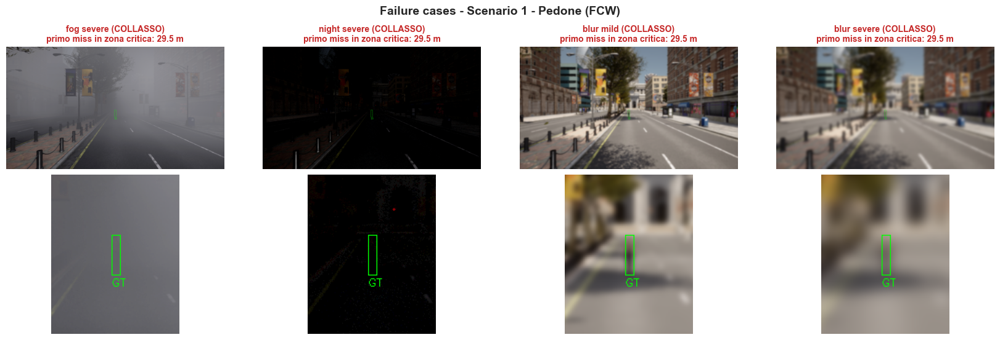

  FAILURE CASES - Scenario 2 - Semaforo (Red Light Warning)
  Condizione     Esito Frame persi rispetto al clear Distanze dei frame persi (m)  Persi in zona critica Primo perso in zona critica (m)
        rain        OK                        2 / 70                  38.4 - 38.4                      0                               -
         fog DEGRADATO                       34 / 70                  16.1 - 38.4                     20                            27.7
       night DEGRADATO                       22 / 70                  21.1 - 38.4                     13                            27.7
   backlight        OK                        6 / 70                  29.1 - 38.4                      0                               -
 rain severe        OK                        0 / 70                            -                      0                               -
  fog severe  COLLASSO                       53 / 70                   9.5 - 38.4                     39              

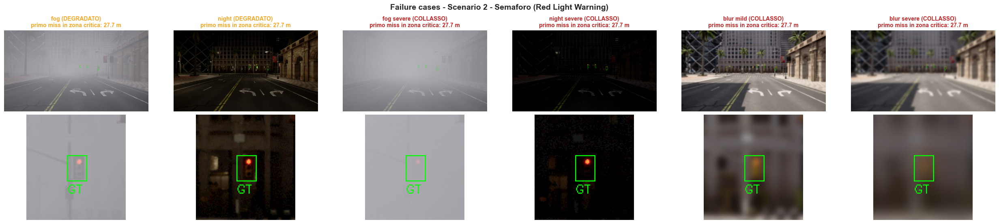

In [80]:
# FAILURE CASES: frame rilevati in clear ma persi nella condizione (ultimo batch)
for key, res in RESULTS.items():
    frames = res['frames']
    latest = frames[frames['batch_dir'] == res['latest']]
    clear = latest[latest['condition'] == 'clear'].set_index('frame_index')
    if clear.empty:
        print(f"{SCENARIOS[key]['name']}: condizione clear assente, confronto non possibile")
        continue
    rows = []
    for cond in res['agg'].index:
        if cond == 'clear':
            continue
        other = latest[latest['condition'] == cond].set_index('frame_index')
        both = clear[['tp', 'distance_m']].join(other[['tp', 'gt_visible', 'in_critical_zone']],
                                                 rsuffix='_cond', how='inner')
        lost = both[(both['tp'] == 1) & (both['tp_cond'] == 0) & (both['gt_visible'] == 1)]
        lost_crit = lost[lost['in_critical_zone'] == 1]
        rows.append({
            'Condizione': cond,
            'Esito': res['agg'].loc[cond, 'esito'],
            'Frame persi rispetto al clear': f"{len(lost)} / {int(both['tp'].sum())}",
            'Distanze dei frame persi (m)': (f"{lost['distance_m'].min():.1f} - {lost['distance_m'].max():.1f}"
                                            if len(lost) else '-'),
            'Persi in zona critica': len(lost_crit),
            'Primo perso in zona critica (m)': f"{lost_crit['distance_m'].max():.1f}" if len(lost_crit) else '-',
        })
    print('=' * 100)
    print(f"  FAILURE CASES - {SCENARIOS[key]['name']}")
    print('=' * 100)
    print(pd.DataFrame(rows).to_string(index=False))
    print()

    # Immagini: primo miss in zona critica per le condizioni non OK
    res['key'] = key
    summary_latest = res['summary'][res['summary']['batch_dir'] == res['latest']]
    labels = dict(zip(summary_latest['condition'], summary_latest['run_label']))
    failing = [c for c in res['agg'].index if res['agg'].loc[c, 'esito'] != 'OK' and c in labels]
    panels = []
    for cond in failing:
        found = sample_with_gt(res, labels[cond], 'miss_crit')
        if found:
            panels.append((cond, found))
    if panels:
        fig, axes = plt.subplots(2, len(panels), figsize=(4.2 * len(panels), 5.6), squeeze=False,
                                 gridspec_kw={'height_ratios': [1, 1.3]})
        for c, (cond, (image, zoom, dist)) in enumerate(panels):
            esito = res['agg'].loc[cond, 'esito']
            axes[0, c].imshow(image)
            axes[0, c].set_title(f"{cond} ({esito})\nprimo miss in zona critica: {dist:.1f} m", fontsize=10,
                                 fontweight='bold', color=VERDICT_COLORS[esito])
            if zoom is not None:
                axes[1, c].imshow(zoom)
            for ax in axes[:, c]:
                ax.axis('off')
        plt.suptitle(f"Failure cases - {SCENARIOS[key]['name']}", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(os.path.join(res['plots_dir'], f'failure_cases_{key}.png'), dpi=150, bbox_inches='tight')
        plt.show()


## 16. Sintesi Automatica dei Risultati

Riepilogo generato dai dati: per ogni scenario, le condizioni raggruppate per esito, la condizione peggiore e la soglia di fallimento rispetto al blur. Il testo stampato è la base per le conclusioni (Sezione 17) e per il report.


In [81]:
# SINTESI AUTOMATICA
for key, res in RESULTS.items():
    agg = res['agg']
    print('=' * 80)
    print(f"  {SCENARIOS[key]['name']}")
    print('=' * 80)
    for esito in ('COLLASSO', 'DEGRADATO', 'OK'):
        rows = agg[agg['esito'] == esito]
        if len(rows):
            items = [f"{c} ({m})" if m else c for c, m in zip(rows.index, rows['motivo'])]
            print(f"  {esito:10s}: {', '.join(items)}")

    others = agg.drop(index='clear', errors='ignore')
    if len(others) and others['critical_recall'].notna().any():
        worst = others['critical_recall'].idxmin()
        print(f"  Condizione peggiore (recall in zona critica): {worst} "
              f"= {agg.loc[worst, 'critical_recall']:.0%}"
              + (f" contro {agg.loc['clear', 'critical_recall']:.0%} in clear" if 'clear' in agg.index else ''))

    steps = [s for s in BLUR_STEPS if s in agg.index]
    if len(steps) == len(BLUR_STEPS):
        esiti = agg.loc[steps, 'esito'].tolist()
        first_bad = next((s for s, e in zip(steps, esiti) if e == 'COLLASSO'), None)
        if first_bad:
            print(f"  Blur: il sistema collassa a partire da '{first_bad}' "
                  f"(esiti: {', '.join(f'{s}={e}' for s, e in zip(steps, esiti))})")
        else:
            print(f"  Blur: nessun collasso fino a blur severe (esiti: {', '.join(esiti)})")
    print()


  Scenario 1 - Pedone (FCW)
  COLLASSO  : fog severe (warning troppo tardi per fermarsi), night severe (warning troppo tardi per fermarsi), blur mild (warning troppo tardi per fermarsi), blur severe (nessun warning)
  OK        : clear, rain, fog, night, backlight, rain severe
  Condizione peggiore (recall in zona critica): blur severe = 2% contro 96% in clear
  Blur: il sistema collassa a partire da 'blur mild' (esiti: clear=OK, blur mild=COLLASSO, blur severe=COLLASSO)

  Scenario 2 - Semaforo (Red Light Warning)
  COLLASSO  : fog severe (warning troppo tardi per fermarsi), night severe (warning troppo tardi per fermarsi), blur mild (warning troppo tardi per fermarsi), blur severe (nessun warning)
  DEGRADATO : fog (recall zona critica al 64% del clear), night (recall zona critica al 77% del clear)
  OK        : clear, rain, backlight, rain severe
  Condizione peggiore (recall in zona critica): blur severe = 0% contro 100% in clear
  Blur: il sistema collassa a partire da 'blur mild'

## 17. Conclusioni

Sintesi dei risultati (2 batch, soglia 0.55, 40 km/h). Metodologia completa, grafici e failure case sono nel report.

| | Pedone (FCW) | Semaforo (Red Light Warning) |
|---|---|---|
| **OK** | clear, rain, fog, night, backlight, rain severe | clear, rain, backlight, rain severe |
| **DEGRADATO** | – | fog, night |
| **COLLASSO** | fog severe, night severe, blur mild, blur severe | fog severe, night severe, blur mild, blur severe |

- **Soglie di fallimento**: nebbia e notte reggono nella versione base e collassano in quella severa (nebbia fitta, notte senza lampioni); il blur collassa già al livello mild.
- **Il collasso è un ritardo, non una cecità**: nelle condizioni severe il target viene ancora rilevato, ma troppo tardi per fermarsi (TTC al warning 0.7–1.4 s, contro gli 1.93 s necessari a 40 km/h). Solo il blur severe annulla la detection.
- **Il semaforo è più fragile del pedone**: target piccolo e lontano, degrada già con fog e night base.
- **Ripetibilità**: i due batch hanno esiti identici in tutte le condizioni e detection uguali nel 99% dei frame.
- **Limiti principali**: rain e backlight non degradano per i limiti del rendering di CARLA (niente gocce sulla lente né abbagliamento visibile); la distanza usata per il TTC è quella reale di CARLA; nello Scenario 2 l'ego entra nella zona di warning ancora in accelerazione (~33 km/h), con la stessa rampa in ogni condizione.
